# Analyse de la Survie des Partis Autoritaires (ARPD) - Panel Data
*Fedi Jouili — Eya Chaabouni*

**Problématique :** Quels facteurs structurels, institutionnels et temporels (conflit, PIB, niveau démocratique) influencent la durée de vie des partis autoritaires ?

## CHANGELOG FINAL (Passage au Panel)
* **Transition Spell → Panel :** Le dataset original était au format "spell" (une ligne par régime). Nous passons au format long (une ligne par parti-année), enrichi par Polity5, V-Dem, UCDP, la Banque Mondiale et le Maddison Project Database (PIB par habitant depuis le XIXe siècle).
* **Périmètre :** Comme dans `final.ipynb`, les juntes (`Party = "N"`) sont exclues : l'unité d'analyse est le parti nommé.
* **Événement / censure :** L'événement est défini par la colonne `Censored` (= 1 ssi le parti est toujours au pouvoir en fin d'observation, `Last Year of Power = "N"`), et non par la présence d'une valeur dans `How Power Ended` (colonne incomplète : certains régimes terminés n'y ont pas de valeur).
* **Covariables institutionnelles :** dans l'ARPD, `Military`, `Violence` et `Occupation` ne décrivent que les régimes sans parti (juntes) ; elles ne sont pas utilisées. `Monarchy` est un codage propre (liste de monarchies vérifiée). `Governance Strategy` n'est codée par Miller (2020) que pour environ un tiers des partis : elle n'est pas imputée et les partis non codés forment une modalité explicite.
* **Double Modélisation :**
    1. Un modèle Cox Statique (covariables mesurées **à l'entrée au pouvoir**, `cluster_col="Country"`).
    2. Un modèle Cox Time-Varying (`CoxTimeVaryingFitter`) avec covariables macro **retardées d'un an** et temps mesuré depuis l'accession au pouvoir (gestion de l'entrée tardive).
* **Risques proportionnels :** les covariables qui violent l'hypothèse (test de Schoenfeld) reçoivent un effet précoce et un effet tardif (seuil de 10 ans). C'est ce modèle corrigé qui est exporté pour l'application web (Sections 6.3 et 7).

## Plan du notebook
0. Configuration & imports
1. Chargement des données panel (exclusion des juntes, contrôles d'intégrité)
2. Audit des nouvelles variables macro
3. Préparation des datasets (statique et time-varying)
4. Analyse exploratoire : Kaplan-Meier par origine
5. Modèles de Cox statique et time-varying
6. Validation des hypothèses et correction de la non-proportionnalité
7. Export pour l'application web
8. Synthèse chiffrée des modèles
9. Interprétation des résultats
10. Limites
11. Conclusion
12. Références bibliographiques

## 0. Configuration & Imports
Chargement des librairies nécessaires.

In [1]:
# ============================================================
# Configuration et imports
# ============================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter, CoxTimeVaryingFitter
from lifelines.statistics import multivariate_logrank_test, proportional_hazard_test
import joblib
from IPython.display import display, Markdown
import warnings

warnings.filterwarnings('ignore')
plt.style.use('dark_background') # Thème Command Center / War Map
%matplotlib inline

RANDOM_STATE = 42
ALPHA = 0.05
PENALIZER = 0.01


## 1. Chargement des données Panel

In [2]:
# ============================================================
# 1.1 Chargement du dataset panel fusionné
# ============================================================
from pathlib import Path

# Racine du projet : fonctionne que le notebook soit lancé depuis la racine ou depuis notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (PROJECT_ROOT / "data").is_dir(), f"Racine du projet introuvable depuis {Path.cwd()}"
SRC_DIR = PROJECT_ROOT / "src"
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "arpd_panel_merged.csv"
df_panel = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dimensions initiales du panel : {df_panel.shape}")


Dimensions initiales du panel : (7109, 71)


### 1.2 Exclusion des juntes et contrôles d'intégrité

Nous excluons les observations `Party = "N"` (juntes), pour rester cohérents avec `final.ipynb`. Nous vérifions ensuite trois propriétés dont dépend la définition de l'événement :
1. `Censored = 1` si et seulement si `Last Year of Power = "N"` (parti toujours au pouvoir) ;
2. chaque spell couvre exactement les années `Year in Power` → `Last Year of Power` ;
3. aucune année n'est dupliquée au sein d'un spell.

In [3]:
# ============================================================
# 1.2 Exclusion des juntes + contrôles d'intégrité
# ============================================================
n_rows_before = len(df_panel)
n_spells_junta = df_panel.loc[df_panel['Party'] == 'N'].groupby(['Country', 'Year in Power']).ngroups
df_panel = df_panel[df_panel['Party'] != 'N'].copy()
print(f"Juntes exclues : {n_rows_before - len(df_panel)} lignes ({n_spells_junta} spells)")

df_panel['spell_id'] = df_panel['Country'] + "_" + df_panel['Party'] + "_" + df_panel['Year in Power'].astype(str)
df_panel = df_panel.sort_values(['spell_id', 'panel_year']).reset_index(drop=True)

spells = df_panel.groupby('spell_id')
ongoing = spells['Last Year of Power'].first().astype(str).eq('N')
censored = spells['Censored'].first().eq(1)
assert (ongoing == censored).all(), "Censored ne correspond pas à Last Year of Power == 'N'"
assert (spells['panel_year'].min() == spells['Year in Power'].first()).all(), "Début de spell incohérent"
assert not df_panel.duplicated(['spell_id', 'panel_year']).any(), "Années dupliquées dans un spell"

print(f"Spells : {spells.ngroups} | terminés (événements) : {(~censored).sum()} | censurés : {censored.sum()}")
print(f"Spells terminés sans valeur 'How Power Ended' : {(~censored & spells['How Power Ended'].last().isna()).sum()}")


Juntes exclues : 2343 lignes (200 spells)
Spells : 277 | terminés (événements) : 246 | censurés : 31
Spells terminés sans valeur 'How Power Ended' : 10


**Remarque.** La dernière ligne montre pourquoi `How Power Ended` ne peut pas servir d'indicateur d'événement : certains régimes terminés n'y ont pas de valeur et auraient été comptés à tort comme censurés. Inversement, la modalité `Continued` désigne un parti qui a **survécu à la démocratisation** : le spell autoritaire s'est bien terminé, c'est donc un événement.

## 2. Audit de Qualité des Nouvelles Variables (Variables Macro)
Avant toute modélisation, nous vérifions le taux de valeurs manquantes (NA) des nouvelles colonnes issues de la fusion.

In [4]:
# ============================================================
# 2.1 Audit des NA
# ============================================================
new_vars = ['gdppc_maddison', 'gdp_per_capita', 'gdp_growth', 'gini', 'oil_rents_pct_gdp',
            'polity2', 'v2x_polyarchy', 'conflict_active']

missing_pct = df_panel[new_vars].isnull().mean() * 100
print("Pourcentage de NA par variable macro :")
print(missing_pct.sort_values(ascending=False).round(2).astype(str) + " %")


Pourcentage de NA par variable macro :
gini                  92.3 %
oil_rents_pct_gdp    51.53 %
gdp_growth           38.25 %
gdp_per_capita       37.22 %
gdppc_maddison       11.88 %
polity2              10.83 %
conflict_active       9.46 %
v2x_polyarchy         3.73 %
dtype: object


**Interprétation (Décision de traitement) :**
* `gini` : > 90% de valeurs manquantes. Nous l'**excluons explicitement**.
* `oil_rents_pct_gdp` : ~50% de NA. Une imputation simple créerait un biais massif et une imputation multiple serait complexe à combiner avec le Cox time-varying. Nous l'**excluons**.
* **PIB** : la série de la Banque Mondiale (`gdp_per_capita`) ne commence qu'en 1960, d'où ~40 % de NA. Nous utilisons à la place le PIB par habitant du **Maddison Project Database 2023** (`gdppc_maddison`, dollars internationaux de 2011), disponible dès le XIXe siècle : il reste environ 12 % de NA (pays non couverts, comme l'Allemagne de l'Est ou la Corée du Nord). Les deux séries n'ont pas la même unité et ne sont pas combinées. Le PIB est utilisé dans le modèle time-varying et comme test de robustesse dans le modèle statique.
* `conflict_active` : UCDP ne commence qu'en 1946. Les années antérieures sont **manquantes** (et non « sans conflit »), ce qui retire du modèle statique les spells ayant débuté avant 1946 et fait entrer plus tard ces spells dans le modèle time-varying.

In [5]:
# ============================================================
# 2.2 Exclusion des variables non viables
# ============================================================
cols_to_drop = ['gini', 'oil_rents_pct_gdp']
df_panel = df_panel.drop(columns=[c for c in cols_to_drop if c in df_panel.columns])
print(f"Variables exclues : {cols_to_drop}")


Variables exclues : ['gini', 'oil_rents_pct_gdp']


## 3. Préparation des Datasets pour la Modélisation

### 3.1 Recodages communs

* **Variables propres aux juntes** : dans l'ARPD, `Military`, `Violence` et `Occupation` ne sont codées que pour les régimes sans parti (juntes). Pour les partis nommés, leurs valeurs dans le panel sont reconstruites par des règles (`Military` vaut 0 pour tous les partis, `Violence` est une fonction exacte de `How Power Gained`) : elles ne sont pas utilisées. L'origine militaire d'un parti reste captée par `Origin = Military`. `Monarchy` est conservée comme **codage propre** (liste de monarchies vérifiée).
* **`Origin`** : les modalités composites rares sont regroupées (`Dictator-Created/Split` et `Dictator-Created/Merger` → `Dictator-Created` ; `Merger` et `Split` → `Merger/Split`). La modalité de référence est `Dictator-Created` (la plus fréquente).
* **`Governance Strategy`** : non imputée (codée par Miller pour environ un tiers des partis). Les stratégies codées sont regroupées en `Policy-Based` (référence), `Repressive` (toute stratégie avec une composante répressive) et `Clientelist` (clientéliste sans répression) ; les partis non codés forment la modalité `Non code`, dont l'effet ne s'interprète pas comme une stratégie.
* **PIB** : PIB par habitant Maddison transformé en logarithme (`log_gdppc`), l'effet d'un écart de PIB étant plus plausiblement proportionnel qu'additif.

In [6]:
# ============================================================
# 3.1 Recodages communs
# ============================================================
print("Valeurs de Military chez les partis nommés :", df_panel['Military'].dropna().unique())

ORIGIN_MAP = {
    'Dictator-Created/Split': 'Dictator-Created',
    'Dictator-Created/Merger': 'Dictator-Created',
    'Merger': 'Merger/Split',
    'Split': 'Merger/Split',
}
ORIGIN_REF = 'Dictator-Created'
df_panel['Origin_grp'] = df_panel['Origin'].replace(ORIGIN_MAP)

GOV_GROUPS = {
    'Policy-Based': 'Policy-Based',
    'Policy-Based/Repressive': 'Repressive',
    'Repressive': 'Repressive',
    'Clientelist/Repressive': 'Repressive',
    'Clientelist': 'Clientelist',
    'Clientelist/Policy-Based': 'Clientelist',
}
GOV_REF = 'Policy-Based'
gov_values = set(df_panel['Governance Strategy'].dropna())
assert gov_values <= set(GOV_GROUPS), f"Strategies non regroupees : {sorted(gov_values - set(GOV_GROUPS))}"
df_panel['Gov_grp'] = df_panel['Governance Strategy'].map(GOV_GROUPS).fillna('Non code')
GOV_COVS = []
for level in ['Repressive', 'Clientelist', 'Non code']:
    df_panel[f'Gov_{level}'] = (df_panel['Gov_grp'] == level).astype(float)
    GOV_COVS.append(f'Gov_{level}')
print(df_panel.groupby('Gov_grp')['spell_id'].nunique().rename('spells').to_string())

df_panel['log_gdppc'] = np.log(df_panel['gdppc_maddison'])   # Maddison 2023, $ internationaux 2011

INST_COVS = ['Marxist?', 'Monarchy'] + GOV_COVS
print(df_panel['Origin_grp'].value_counts())


Valeurs de Military chez les partis nommés : [0.]
Gov_grp
Clientelist      12
Non code        189
Policy-Based     33
Repressive       43
Origin_grp
Dictator-Created    1069
Communist            987
Elite Coalition      830
Revolution           726
Independence         701
Merger/Split         234
Military             219
Name: count, dtype: int64


### 3.2 Dataset Statique (une ligne par spell)

Chaque spell est résumé par ses caractéristiques **à l'entrée au pouvoir** :
* `duration` = `Last Year of Power` − `Year in Power` + 1 (fin d'observation pour les spells censurés) ;
* `event` = 1 − `Censored` ;
* `polity2_entry`, `conflict_entry`, `log_gdppc_entry` : valeurs de la première année du spell. Une valeur manquante cette année-là reste manquante : elle n'est pas remplacée par celle d'une année ultérieure, ce qui introduirait une information future.

Utiliser la moyenne du PIB ou le maximum de conflit sur toute la durée introduirait une **information future** : un régime qui dure plus longtemps a mécaniquement plus d'années pour connaître un conflit, ce qui fausse le hazard ratio. Les valeurs à l'entrée sont aussi celles qu'un utilisateur de l'application web peut renseigner pour un profil de régime.

In [7]:
# ============================================================
# 3.2 Création du Dataset Statique (df_static)
# ============================================================
# Première et dernière ANNÉE de chaque spell. groupby().first() ne convient pas : il saute les
# valeurs manquantes et prendrait la première valeur disponible (parfois des décennies après
# l'entrée au pouvoir), ce qui introduirait une information future dans le modèle statique.
ordered = df_panel.sort_values(['spell_id', 'panel_year'])
first = ordered.drop_duplicates('spell_id', keep='first').set_index('spell_id')
last = ordered.drop_duplicates('spell_id', keep='last').set_index('spell_id')

df_static = pd.DataFrame({
    'Country': first['Country'],
    'duration': last['panel_year'] - first['Year in Power'] + 1,
    'event': (1 - first['Censored']).astype(int),
    'Origin_grp': first['Origin_grp'],
    **{c: first[c] for c in INST_COVS},
    'polity2_entry': first['polity2'],
    'conflict_entry': first['conflict_active'],
    'log_gdppc_entry': first['log_gdppc'],
})
print(f"Spells : {len(df_static)} | événements : {df_static['event'].sum()} | censurés : {(1 - df_static['event']).sum()}")
print("NA par colonne :", df_static.isna().sum()[lambda s: s > 0].to_dict())

def encode_static(df, covs):
    out = df[['Country', 'duration', 'event', 'Origin_grp'] + covs].dropna()
    out = pd.get_dummies(out, columns=['Origin_grp'], prefix='Origin', dtype=float)
    out = out.drop(columns=f'Origin_{ORIGIN_REF}')
    num_cols = [c for c in out.columns if c != 'Country']
    out[num_cols] = out[num_cols].astype(float)
    return out

STATIC_COVS = INST_COVS + ['polity2_entry', 'conflict_entry']
df_model = df_static[['Country', 'duration', 'event', 'Origin_grp'] + STATIC_COVS].dropna().copy()
df_model_encoded = encode_static(df_static, STATIC_COVS)
print(f"Dataset statique principal : {len(df_model_encoded)} spells, {int(df_model_encoded['event'].sum())} événements, "
      f"{len(df_model_encoded.columns) - 3} covariables")


Spells : 277 | événements : 246 | censurés : 31
NA par colonne : {'polity2_entry': 20, 'conflict_entry': 36, 'log_gdppc_entry': 37}
Dataset statique principal : 224 spells, 195 événements, 13 covariables


### 3.3 Dataset Time-Varying (format start / stop)

Chaque ligne parti-année devient un intervalle `(start, stop]` où **le temps est mesuré depuis l'accession au pouvoir** : `start = panel_year − Year in Power`. Trois points méritent attention :

1. **Événement** : placé sur la dernière année du spell, uniquement si le spell n'est pas censuré.
2. **Retard d'un an (lag)** : les covariables macro de l'année *t−1* expliquent le risque de chute à l'année *t*. Sans ce décalage, `polity2` mesurée l'année de la chute reflète la transition elle-même (le score démocratique bondit au moment où le régime tombe), ce qui crée une causalité inverse. Le lag est calculé au niveau pays-année, de sorte que la première année d'un spell utilise la valeur de l'année précédente du pays.
3. **Données manquantes et entrée tardive** : les valeurs manquantes sont propagées vers l'avant au sein d'un spell (*last observation carried forward*), puis les intervalles encore incomplets sont retirés. Comme `start` reste ancré sur l'accession au pouvoir, un spell débutant en 1930 dont l'état de conflit n'est connu qu'à partir de 1946 (début d'UCDP) entre dans le *risk set* à `start = 16` : c'est une **troncature à gauche**, que le format counting-process de `CoxTimeVaryingFitter` gère correctement. L'ancienne version (`cumcount()` après suppression des NA) remettait au contraire l'horloge à zéro.

In [8]:
# ============================================================
# 3.3 Création du Dataset Time-Varying (df_tv)
# ============================================================
MACRO_VARS = ['log_gdppc', 'polity2', 'conflict_active']
TV_COVS = [f"{v}_lag1" for v in MACRO_VARS]

# Lag d'un an calculé au niveau pays-année (valeurs macro identiques pour tous les spells d'un même pays-année)
country_year = (df_panel.groupby(['Country', 'panel_year'])[MACRO_VARS].first()
                .reset_index().sort_values(['Country', 'panel_year']))
consecutive = country_year.groupby('Country')['panel_year'].diff().eq(1)
for v in MACRO_VARS:
    country_year[f"{v}_lag1"] = country_year.groupby('Country')[v].shift(1).where(consecutive)

df_tv = df_panel.merge(country_year[['Country', 'panel_year'] + TV_COVS], on=['Country', 'panel_year'], how='left')
df_tv = df_tv.sort_values(['spell_id', 'panel_year']).reset_index(drop=True)

df_tv['start'] = df_tv['panel_year'] - df_tv['Year in Power']
df_tv['stop'] = df_tv['start'] + 1
is_last = df_tv['spell_id'] != df_tv['spell_id'].shift(-1)
df_tv['event'] = (is_last & df_tv['Censored'].eq(0)).astype(int)
assert df_tv.groupby('spell_id')['event'].sum().max() <= 1
assert df_tv['event'].sum() == df_static['event'].sum()

# LOCF au sein d'un spell, puis suppression des intervalles incomplets
df_tv[TV_COVS] = df_tv.groupby('spell_id')[TV_COVS].ffill()
n_events_all = df_tv['event'].sum()
df_tv = df_tv.dropna(subset=TV_COVS + INST_COVS + ['Origin_grp'])

df_tv_encoded = pd.get_dummies(
    df_tv[['spell_id', 'start', 'stop', 'event', 'Origin_grp'] + INST_COVS + TV_COVS],
    columns=['Origin_grp'], prefix='Origin', dtype=float,
).drop(columns=f'Origin_{ORIGIN_REF}')
num_cols = [c for c in df_tv_encoded.columns if c != 'spell_id']
df_tv_encoded[num_cols] = df_tv_encoded[num_cols].astype(float)

entry = df_tv.groupby('spell_id')['start'].min()
print(f"Intervalles : {len(df_tv_encoded)} | spells : {df_tv['spell_id'].nunique()} | "
      f"événements conservés : {int(df_tv['event'].sum())} / {n_events_all}")
print(f"Spells à entrée tardive (start > 0) : {(entry > 0).sum()}")


Intervalles : 3655 | spells : 222 | événements conservés : 193 / 246


Spells à entrée tardive (start > 0) : 172


## 4. Analyse Exploratoire & Courbes Kaplan-Meier
Nous conservons les diagnostics fonctionnels sur le dataset statique.

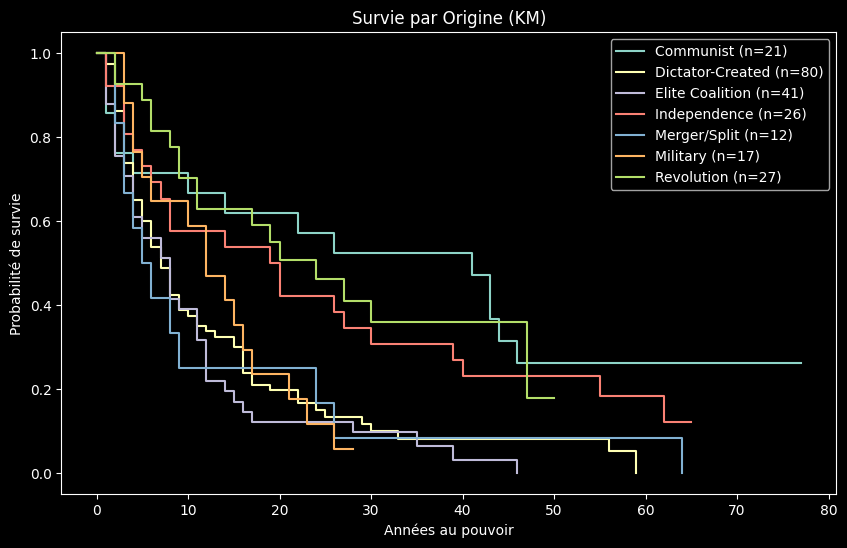

Log-rank multivarié (Origin) : chi2 = 32.86, p = 0.0000


In [9]:
# ============================================================
# 4.1 Kaplan-Meier par Origin + test log-rank
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))
kmf = KaplanMeierFitter()

for origin in sorted(df_model['Origin_grp'].unique()):
    mask = df_model['Origin_grp'] == origin
    kmf.fit(df_model.loc[mask, 'duration'], df_model.loc[mask, 'event'], label=f"{origin} (n={mask.sum()})")
    kmf.plot_survival_function(ax=ax, ci_show=False)

ax.set_title("Survie par Origine (KM)")
ax.set_ylabel("Probabilité de survie")
ax.set_xlabel("Années au pouvoir")
plt.show()

lr = multivariate_logrank_test(df_model['duration'], df_model['Origin_grp'], df_model['event'])
print(f"Log-rank multivarié (Origin) : chi2 = {lr.test_statistic:.2f}, p = {lr.p_value:.4f}")


## 5. Deux Modèles en Parallèle

Nous allons confronter :
1. **Un modèle de Cox statique**, utile pour sa robustesse et sa facilité d'export pour l'application Web. Nous y ajoutons `cluster_col="Country"` pour regrouper les erreurs standards (spells multiples par pays).
2. **Un modèle de Cox Time-Varying**.

**Pourquoi le Time-Varying est statistiquement plus correct pour les variables macro ?**
Le modèle statique ne voit que la situation à l'entrée au pouvoir. Si un pays subit une crise économique la 15ème année qui provoque la chute du régime, cette information est invisible. Le format Time-Varying (start/stop) évalue le risque (hazard) à l'année $t$ en fonction du PIB, du score Polity2 et de l'état de conflit à l'année $t-1$, capturant les chocs en cours de mandat sans utiliser d'information future.

In [10]:
# ============================================================
# 5.1 Modèle Cox Statique (avec erreurs standards robustes)
# ============================================================
cph_static = CoxPHFitter(penalizer=PENALIZER) # Légère pénalisation pour stabilité
cph_static.fit(df_model_encoded, duration_col='duration', event_col='event', cluster_col='Country')

print("=== Modèle de Cox Statique (covariables à l'entrée) ===")
cph_static.print_summary(columns=['coef', 'exp(coef)', 'se(coef)', 'p', 'exp(coef) lower 95%', 'exp(coef) upper 95%'], style="ascii")


=== Modèle de Cox Statique (covariables à l'entrée) ===
<lifelines.CoxPHFitter: fitted with 224 total observations, 29 right-censored observations>
             duration col = 'duration'
                event col = 'event'
              cluster col = 'Country'
                penalizer = 0.01
                 l1 ratio = 0.0
          robust variance = True
      baseline estimation = breslow
   number of observations = 224
number of events observed = 195
   partial log-likelihood = -876.61
         time fit was run = 2026-10-02 18:17:40 UTC

---
                        coef exp(coef)  se(coef) exp(coef) lower 95% exp(coef) upper 95%      p
covariate                                                                                      
Marxist?               -0.17      0.84      0.17                0.61                1.18   0.32
Monarchy                0.53      1.70      0.17                1.21                2.38 <0.005
Gov_Repressive         -0.20      0.82      0.24                

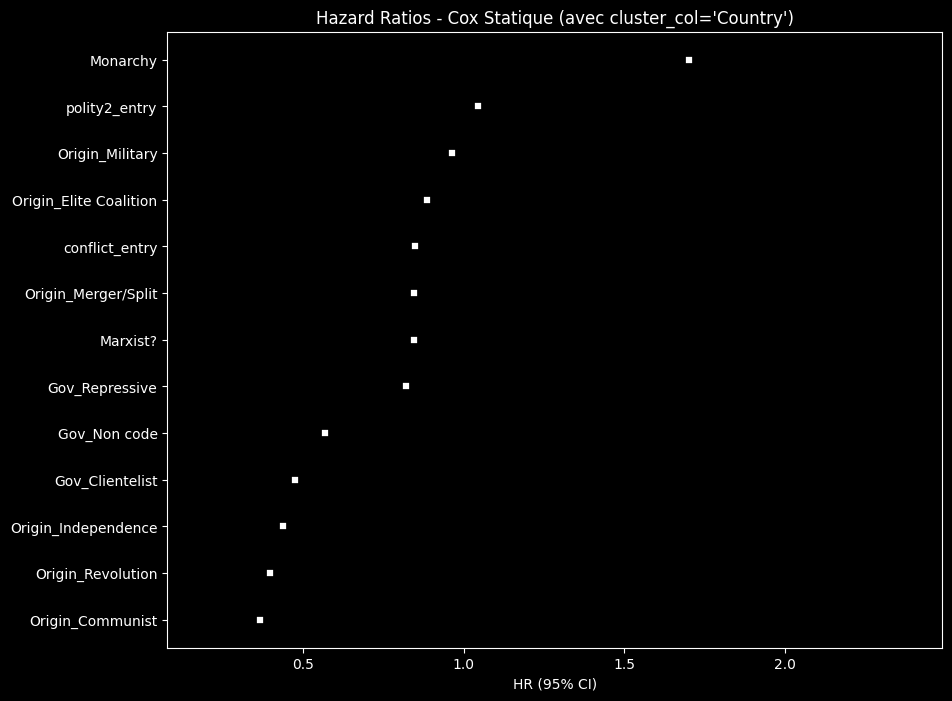

In [11]:
# ============================================================
# 5.1.b Forest Plot du Cox Statique
# ============================================================
plt.figure(figsize=(10, 8))
cph_static.plot(hazard_ratios=True)
plt.title("Hazard Ratios - Cox Statique (avec cluster_col='Country')")
plt.show()


### 5.1.c Robustesse : ajout du PIB à l'entrée

Le PIB Maddison manque pour certains pays (environ 12 % des parti-années) : l'ajouter au modèle statique réduit l'échantillon. Nous l'estimons séparément pour vérifier que les effets institutionnels restent stables.

In [12]:
# ============================================================
# 5.1.c Cox Statique + log PIB à l'entrée
# ============================================================
df_model_gdp = encode_static(df_static, STATIC_COVS + ['log_gdppc_entry'])
cph_static_gdp = CoxPHFitter(penalizer=PENALIZER)
cph_static_gdp.fit(df_model_gdp, duration_col='duration', event_col='event', cluster_col='Country')
print(f"Échantillon : {len(df_model_gdp)} spells, {int(df_model_gdp['event'].sum())} événements")
cph_static_gdp.print_summary(columns=['exp(coef)', 'p', 'exp(coef) lower 95%', 'exp(coef) upper 95%'], style="ascii")


Échantillon : 203 spells, 178 événements
<lifelines.CoxPHFitter: fitted with 203 total observations, 25 right-censored observations>
             duration col = 'duration'
                event col = 'event'
              cluster col = 'Country'
                penalizer = 0.01
                 l1 ratio = 0.0
          robust variance = True
      baseline estimation = breslow
   number of observations = 203
number of events observed = 178
   partial log-likelihood = -784.57
         time fit was run = 2026-10-02 18:17:40 UTC

---
                       exp(coef) exp(coef) lower 95% exp(coef) upper 95%      p
covariate                                                                      
Marxist?                    0.90                0.64                1.26   0.52
Monarchy                    1.58                1.08                2.30   0.02
Gov_Repressive              0.72                0.43                1.21   0.21
Gov_Clientelist             0.35                0.20           

In [13]:
# ============================================================
# 5.2 Modèle Cox Time-Varying
# ============================================================
ctv = CoxTimeVaryingFitter(penalizer=PENALIZER)
ctv.fit(df_tv_encoded, id_col='spell_id', start_col='start', stop_col='stop', event_col='event', show_progress=False)

print("=== Modèle de Cox Time-Varying (macro retardées d'un an) ===")
ctv.print_summary(columns=['coef', 'exp(coef)', 'se(coef)', 'p', 'exp(coef) lower 95%', 'exp(coef) upper 95%'], style="ascii")


=== Modèle de Cox Time-Varying (macro retardées d'un an) ===
<lifelines.CoxTimeVaryingFitter: fitted with 3655 periods, 222 subjects, 193 events>
         event col = 'event'
         penalizer = 0.01
number of subjects = 222
 number of periods = 3655
  number of events = 193
partial log-likelihood = -838.23
  time fit was run = 2026-10-02 18:17:40 UTC

---
                        coef exp(coef)  se(coef) exp(coef) lower 95% exp(coef) upper 95%      p
covariate                                                                                      
Marxist?               -0.27      0.76      0.18                0.54                1.09   0.13
Monarchy                0.24      1.27      0.23                0.81                2.00   0.30
Gov_Repressive         -0.07      0.93      0.22                0.60                1.44   0.75
Gov_Clientelist        -0.71      0.49      0.36                0.24                0.99   0.05
Gov_Non code           -0.47      0.63      0.19                

### 5.3 Tableau Récapitulatif

Les trois modèles ne sont pas estimés sur le même échantillon, leurs log-vraisemblances ne sont donc pas comparables. `CoxTimeVaryingFitter` ne fournit pas non plus de C-index (la concordance n'est pas définie de façon standard avec des covariables qui changent dans le temps). Nous comparons donc les **hazard ratios** des covariables communes.

In [14]:
# ============================================================
# 5.3 Tableau Récapitulatif
# ============================================================
def hr_table(model, name):
    s = model.summary
    return pd.DataFrame({
        f"HR {name}": s['exp(coef)'].round(3),
        f"p {name}": s['p'].round(3),
    })

comparison = pd.concat([
    hr_table(cph_static, 'statique'),
    hr_table(cph_static_gdp, 'statique+PIB'),
    hr_table(ctv, 'time-varying'),
], axis=1)
display(comparison)

print(f"C-index (Statique)       : {cph_static.concordance_index_:.4f}  (n = {len(df_model_encoded)})")
print(f"C-index (Statique + PIB) : {cph_static_gdp.concordance_index_:.4f}  (n = {len(df_model_gdp)})")


,HR statique,p statique,HR statique+PIB,p statique+PIB,HR time-varying,p time-varying
covariate,,,,,,
Marxist?,0.844,0.316,0.896,0.524,0.764,0.133
Monarchy,1.700,0.002,1.580,0.017,1.272,0.297
Gov_Repressive,0.819,0.403,0.720,0.212,0.930,0.746
Gov_Clientelist,0.474,0.008,0.348,0.000,0.489,0.045
Gov_Non code,0.567,0.001,0.486,0.000,0.626,0.016
polity2_entry,1.043,0.002,1.040,0.006,NaN,NaN
conflict_entry,0.847,0.335,0.893,0.524,NaN,NaN
Origin_Communist,0.366,0.003,0.446,0.045,0.562,0.024
Origin_Elite Coalition,0.886,0.551,0.916,0.677,0.879,0.505


C-index (Statique)       : 0.6473  (n = 224)
C-index (Statique + PIB) : 0.6418  (n = 203)


### 5.4 Robustesse : V-Dem au lieu de Polity2

Polity5 s'arrête en 2018, alors que l'indice de démocratie électorale de V-Dem (`v2x_polyarchy`, de 0 à 1) couvre le panel jusqu'en 2024. Nous ré-estimons les modèles statique (5.1) et time-varying (5.2) en remplaçant Polity2 par V-Dem, avec exactement la même construction : valeur de la **première année** du spell pour le modèle statique (première ligne du spell, et non la première valeur disponible), valeur de l'**année précédente** calculée au niveau pays-année pour le modèle time-varying. V-Dem est exprimé **par 0,1 point** pour que son hazard ratio soit lisible. Ces jeux de données sont construits à part : les modèles principaux, la correction de la non-proportionnalité et les exports de la Section 7 ne changent pas.

**Critère, fixé avant les résultats :** un résultat est **robuste** s'il garde le même sens et la même significativité au seuil $\alpha$ (significatif dans les deux modèles, ou dans aucun) avec Polity2 et avec V-Dem.

In [15]:
# ============================================================
# 5.4 Robustesse : V-Dem au lieu de Polity2
# ============================================================
from scipy import stats

VDEM_SCALE = 10   # hazard ratio pour 0,1 point de v2x_polyarchy (échelle 0-1)
NON_CODED_COL = "Gov_Non code"

# --- Corrélation Polity2 / V-Dem sur les parti-années où les deux existent
both = df_panel[["polity2", "v2x_polyarchy"]].dropna()
r_pearson = both["polity2"].corr(both["v2x_polyarchy"])
rho_spearman = stats.spearmanr(both["polity2"], both["v2x_polyarchy"])[0]

# --- Modèle statique : valeur V-Dem de la première année du spell (`first` = première ligne, Section 3.2)
df_static_vdem = df_static.drop(columns=["polity2_entry"]).assign(vdem_entry=first["v2x_polyarchy"] * VDEM_SCALE)
STATIC_COVS_VDEM = INST_COVS + ["vdem_entry", "conflict_entry"]
df_model_vdem = encode_static(df_static_vdem, STATIC_COVS_VDEM)
cph_static_vdem = CoxPHFitter(penalizer=PENALIZER).fit(
    df_model_vdem, duration_col="duration", event_col="event", cluster_col="Country")

# --- Modèle time-varying : V-Dem de l'année précédente, retard calculé au niveau pays-année (comme en 3.3)
MACRO_VARS_VDEM = ["log_gdppc", "v2x_polyarchy", "conflict_active"]
TV_COVS_VDEM = ["log_gdppc_lag1", "vdem_lag1", "conflict_active_lag1"]
cy_vdem = (df_panel.groupby(["Country", "panel_year"])[MACRO_VARS_VDEM].first()
           .reset_index().sort_values(["Country", "panel_year"]))
consecutive_vdem = cy_vdem.groupby("Country")["panel_year"].diff().eq(1)
for v, lag in zip(MACRO_VARS_VDEM, TV_COVS_VDEM):
    cy_vdem[lag] = cy_vdem.groupby("Country")[v].shift(1).where(consecutive_vdem)
cy_vdem["vdem_lag1"] = cy_vdem["vdem_lag1"] * VDEM_SCALE

df_tv_vdem = (df_panel.merge(cy_vdem[["Country", "panel_year"] + TV_COVS_VDEM], on=["Country", "panel_year"], how="left")
              .sort_values(["spell_id", "panel_year"]).reset_index(drop=True))
df_tv_vdem["start"] = df_tv_vdem["panel_year"] - df_tv_vdem["Year in Power"]
df_tv_vdem["stop"] = df_tv_vdem["start"] + 1
last_row_vdem = df_tv_vdem["spell_id"] != df_tv_vdem["spell_id"].shift(-1)
df_tv_vdem["event"] = (last_row_vdem & df_tv_vdem["Censored"].eq(0)).astype(int)
assert df_tv_vdem["event"].sum() == n_events_all
df_tv_vdem[TV_COVS_VDEM] = df_tv_vdem.groupby("spell_id")[TV_COVS_VDEM].ffill()
df_tv_vdem = df_tv_vdem.dropna(subset=TV_COVS_VDEM + INST_COVS + ["Origin_grp"])
df_tv_vdem_encoded = pd.get_dummies(
    df_tv_vdem[["spell_id", "start", "stop", "event", "Origin_grp"] + INST_COVS + TV_COVS_VDEM],
    columns=["Origin_grp"], prefix="Origin", dtype=float,
).drop(columns=f"Origin_{ORIGIN_REF}")
cols_vdem = [c for c in df_tv_vdem_encoded.columns if c != "spell_id"]
df_tv_vdem_encoded[cols_vdem] = df_tv_vdem_encoded[cols_vdem].astype(float)
ctv_vdem = CoxTimeVaryingFitter(penalizer=PENALIZER).fit(
    df_tv_vdem_encoded, id_col="spell_id", start_col="start", stop_col="stop", event_col="event", show_progress=False)

# --- Effectifs
samples_vdem = pd.DataFrame({
    "spells": [len(df_model_encoded), len(df_model_vdem), df_tv_encoded["spell_id"].nunique(), df_tv_vdem_encoded["spell_id"].nunique()],
    "chutes": [int(df_model_encoded["event"].sum()), int(df_model_vdem["event"].sum()),
               int(df_tv_encoded["event"].sum()), int(df_tv_vdem_encoded["event"].sum())],
    "lignes": [len(df_model_encoded), len(df_model_vdem), len(df_tv_encoded), len(df_tv_vdem_encoded)],
}, index=["Statique, Polity2", "Statique, V-Dem", "Time-varying, Polity2", "Time-varying, V-Dem"])
display(samples_vdem)


# --- Tableau de robustesse (critère annoncé ci-dessus)
def robustness_table(model_polity, model_vdem, polity_var, vdem_var):
    s_pol, s_vdem = model_polity.summary, model_vdem.summary
    rows = []
    for var in s_pol.index:
        other = vdem_var if var == polity_var else var
        if other not in s_vdem.index:
            continue
        hr_p, p_p = s_pol.loc[var, "exp(coef)"], s_pol.loc[var, "p"]
        hr_v, p_v = s_vdem.loc[other, "exp(coef)"], s_vdem.loc[other, "p"]
        rows.append({"covariable": var if var != polity_var else "niveau démocratique",
                     "HR Polity2": hr_p, "p Polity2": p_p, "HR V-Dem": hr_v, "p V-Dem": p_v,
                     "robuste": bool(np.sign(np.log(hr_p)) == np.sign(np.log(hr_v)) and (p_p < ALPHA) == (p_v < ALPHA))})
    return pd.DataFrame(rows).set_index("covariable")


robust_static = robustness_table(cph_static, cph_static_vdem, "polity2_entry", "vdem_entry")
robust_tv = robustness_table(ctv, ctv_vdem, "polity2_lag1", "vdem_lag1")
for name, tab in [("Modèle statique (5.1)", robust_static), ("Modèle time-varying (5.2)", robust_tv)]:
    display(Markdown(f"**{name}** — Polity2 (par point) contre V-Dem (par 0,1 point) :"))
    display(tab.round(3))


def robust_summary(tab):
    substantive = tab.drop(index=[NON_CODED_COL], errors="ignore")
    sig_any = substantive[(substantive["p Polity2"] < ALPHA) | (substantive["p V-Dem"] < ALPHA)]
    return substantive, sig_any


subst_s, sig_s = robust_summary(robust_static)
subst_t, sig_t = robust_summary(robust_tv)
dem_s, dem_t = robust_static.loc["niveau démocratique"], robust_tv.loc["niveau démocratique"]


def dem_sentence(row, label):
    sens = "augmente" if row["HR V-Dem"] > 1 else "réduit"
    return (f"dans le modèle {label}, un niveau démocratique plus élevé {sens} le risque de chute avec V-Dem "
            f"(HR = {row['HR V-Dem']:.2f} par 0,1 point, p = {row['p V-Dem']:.3f}) comme avec Polity2 "
            f"(HR = {row['HR Polity2']:.2f} par point, p = {row['p Polity2']:.3f})" if row["robuste"] else
            f"dans le modèle {label}, l'effet du niveau démocratique n'est pas robuste au changement de mesure "
            f"(Polity2 : HR = {row['HR Polity2']:.2f}, p = {row['p Polity2']:.3f} ; V-Dem : HR = {row['HR V-Dem']:.2f}, "
            f"p = {row['p V-Dem']:.3f})")


events_gained = int(df_tv_vdem_encoded["event"].sum()) - int(df_tv_encoded["event"].sum())
not_robust = [v for tab in (sig_s, sig_t) for v in tab.index[~tab["robuste"]]]
vdem_summary = (
    f"Sur les {len(both)} parti-années où les deux mesures existent, Polity2 et V-Dem sont fortement liés "
    f"(corrélation de Pearson {r_pearson:.2f}, de Spearman {rho_spearman:.2f}). Avec V-Dem, le modèle time-varying "
    f"conserve {int(df_tv_vdem_encoded['event'].sum())} chutes contre {int(df_tv_encoded['event'].sum())} avec Polity2 "
    f"({events_gained:+d}), et le modèle statique {int(df_model_vdem['event'].sum())} contre "
    f"{int(df_model_encoded['event'].sum())}. {dem_sentence(dem_s, 'statique')[0].upper() + dem_sentence(dem_s, 'statique')[1:]} ; "
    f"{dem_sentence(dem_t, 'time-varying')}. Parmi les covariables significatives dans au moins une des deux versions, "
    f"{int(sig_s['robuste'].sum())} sur {len(sig_s)} sont robustes dans le modèle statique et "
    f"{int(sig_t['robuste'].sum())} sur {len(sig_t)} dans le modèle time-varying"
    + (f" (non robustes : {', '.join(f'`{v}`' for v in not_robust)})." if not_robust else ".")
    + f" La modalité `{NON_CODED_COL}` n'entre pas dans ce décompte (ce n'est pas une stratégie)."
)
display(Markdown("**Synthèse.** " + vdem_summary))


,spells,chutes,lignes
"Statique, Polity2",224,195,224
"Statique, V-Dem",235,205,235
"Time-varying, Polity2",222,193,3655
"Time-varying, V-Dem",227,198,3746


**Modèle statique (5.1)** — Polity2 (par point) contre V-Dem (par 0,1 point) :

,HR Polity2,p Polity2,HR V-Dem,p V-Dem,robuste
covariable,,,,,
Marxist?,0.844,0.316,0.793,0.173,True
Monarchy,1.700,0.002,1.484,0.033,True
Gov_Repressive,0.819,0.403,0.862,0.537,True
Gov_Clientelist,0.474,0.008,0.525,0.038,True
Gov_Non code,0.567,0.001,0.597,0.007,True
niveau démocratique,1.043,0.002,1.247,0.001,True
conflict_entry,0.847,0.335,0.869,0.419,True
Origin_Communist,0.366,0.003,0.401,0.007,True
Origin_Elite Coalition,0.886,0.551,0.983,0.931,True


**Modèle time-varying (5.2)** — Polity2 (par point) contre V-Dem (par 0,1 point) :

,HR Polity2,p Polity2,HR V-Dem,p V-Dem,robuste
covariable,,,,,
Marxist?,0.764,0.133,0.740,0.083,True
Monarchy,1.272,0.297,1.258,0.322,True
Gov_Repressive,0.930,0.746,0.962,0.864,True
Gov_Clientelist,0.489,0.045,0.493,0.049,True
Gov_Non code,0.626,0.016,0.645,0.021,True
log_gdppc_lag1,0.888,0.155,0.893,0.164,True
niveau démocratique,1.052,0.001,1.219,0.000,True
conflict_active_lag1,1.382,0.039,1.464,0.014,True
Origin_Communist,0.562,0.024,0.604,0.047,True


**Synthèse.** Sur les 4233 parti-années où les deux mesures existent, Polity2 et V-Dem sont fortement liés (corrélation de Pearson 0.70, de Spearman 0.68). Avec V-Dem, le modèle time-varying conserve 198 chutes contre 193 avec Polity2 (+5), et le modèle statique 205 contre 195. Dans le modèle statique, un niveau démocratique plus élevé augmente le risque de chute avec V-Dem (HR = 1.25 par 0,1 point, p = 0.001) comme avec Polity2 (HR = 1.04 par point, p = 0.002) ; dans le modèle time-varying, un niveau démocratique plus élevé augmente le risque de chute avec V-Dem (HR = 1.22 par 0,1 point, p = 0.000) comme avec Polity2 (HR = 1.05 par point, p = 0.001). Parmi les covariables significatives dans au moins une des deux versions, 6 sur 6 sont robustes dans le modèle statique et 6 sur 6 dans le modèle time-varying. La modalité `Gov_Non code` n'entre pas dans ce décompte (ce n'est pas une stratégie).

## 6. Validation des Hypothèses & Robustesse


   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...



The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'Monarchy' failed the non-proportional test: p-value is 0.0402.

   Advice: with so few unique values (only 2), you can include `strata=['Monarchy', ...]` in the
call in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...



...


   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




   Bootstrapping lowess lines. May take a moment...




---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



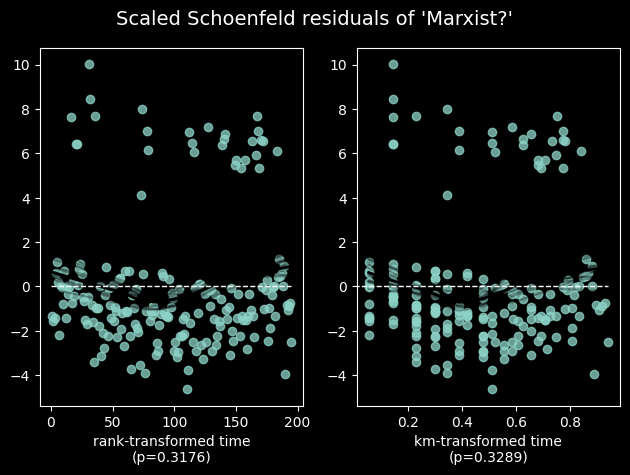

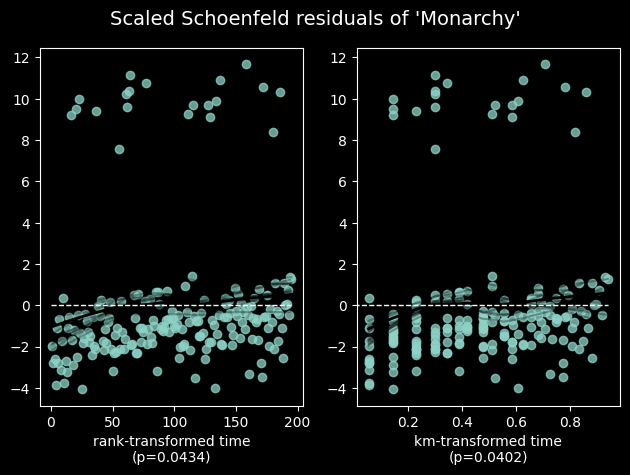

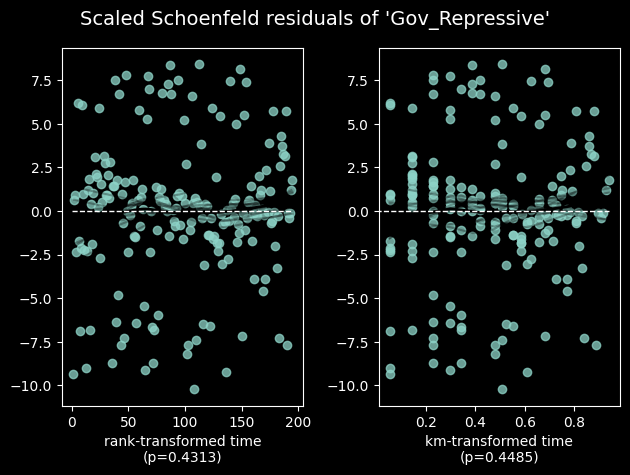

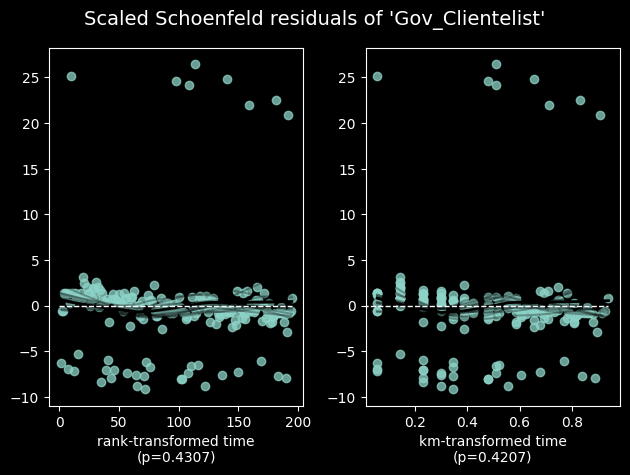

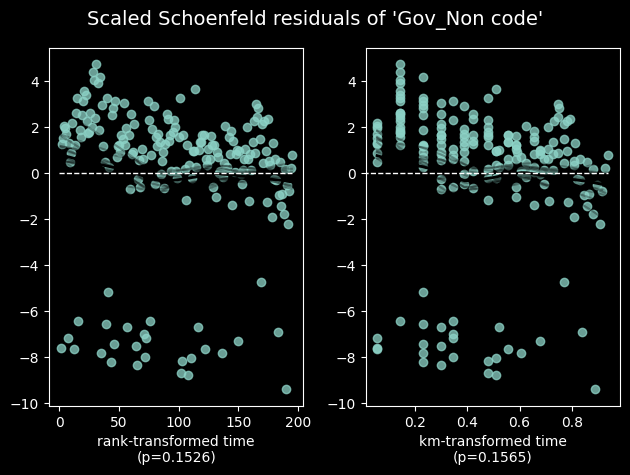

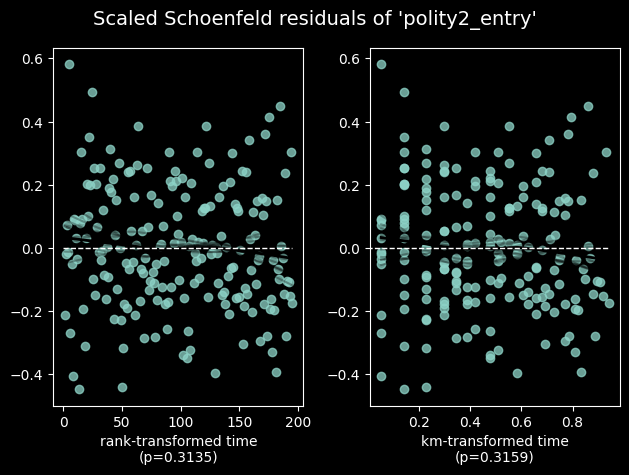

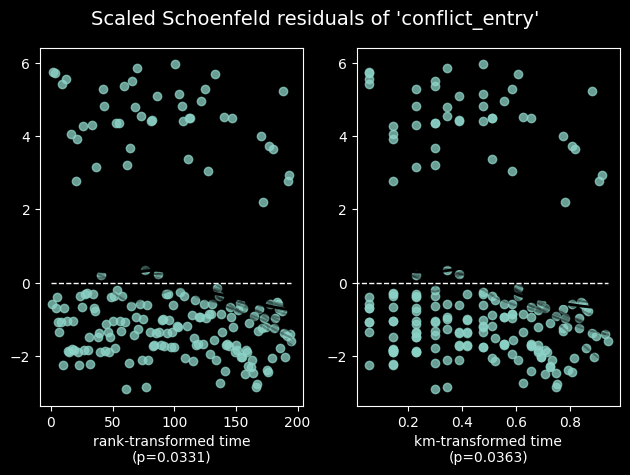

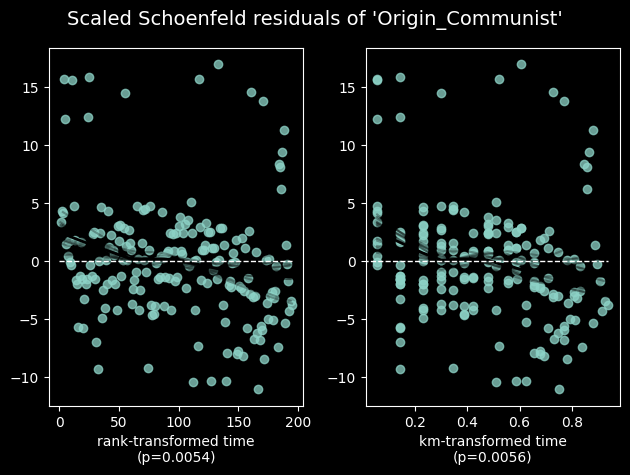

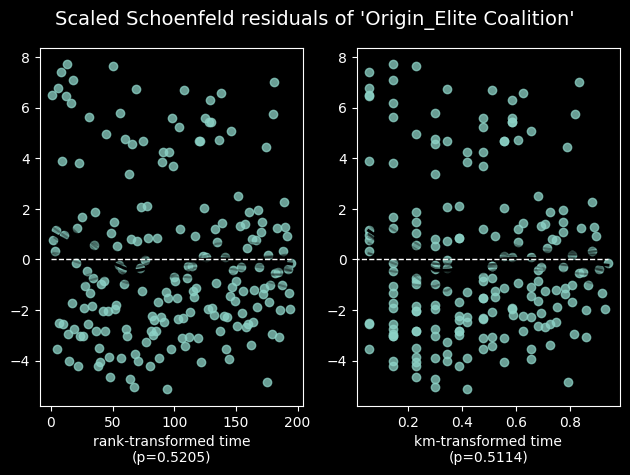

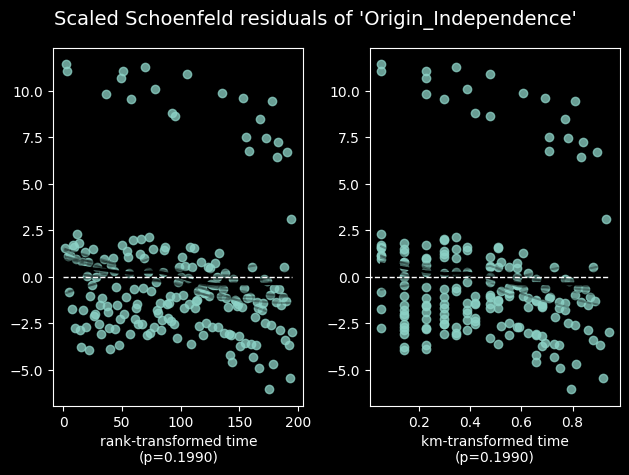

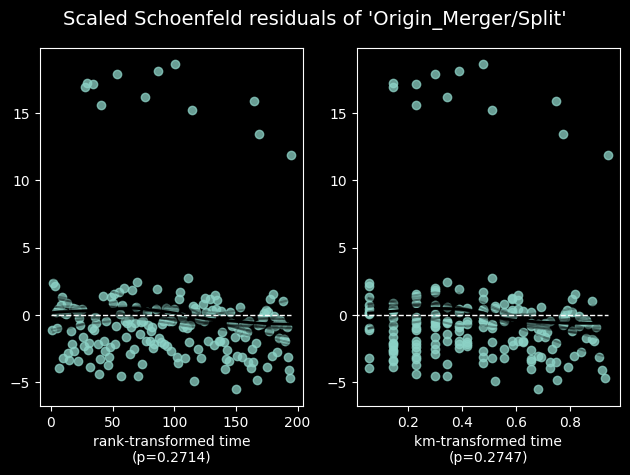

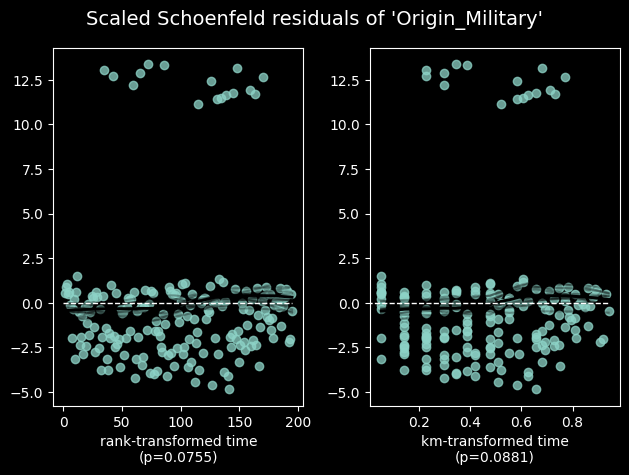

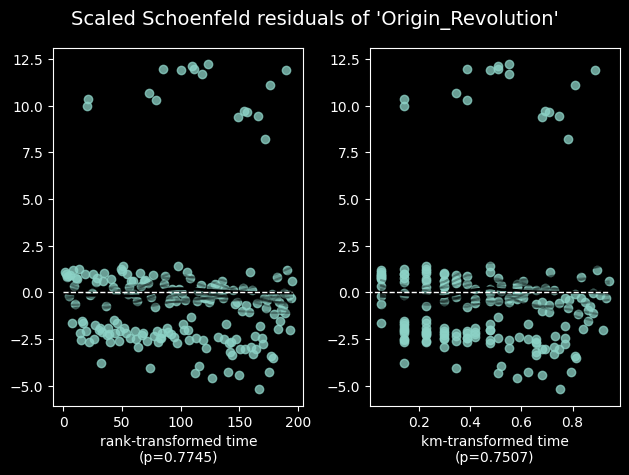

In [16]:
# ============================================================
# 6.1 Test de Schoenfeld (Cox Statique)
# ============================================================
try:
    cph_static.check_assumptions(df_model_encoded, p_value_threshold=ALPHA, show_plots=True)
except Exception as e:
    print(f"Schoenfeld plot note: {e}")


In [17]:
# ============================================================
# 6.1.b Liste des violations (test de Schoenfeld, transformation rang)
# ============================================================
ph_test = proportional_hazard_test(cph_static, df_model_encoded, time_transform='rank')
ph_violations = ph_test.summary.index[ph_test.summary['p'] < ALPHA].tolist()
display(ph_test.summary.loc[ph_violations, ['test_statistic', 'p']].round(4))
print("Covariables violant l'hypothèse PH :", ph_violations)


,test_statistic,p
Monarchy,4.0811,0.0434
Origin_Communist,7.7501,0.0054
conflict_entry,4.5424,0.0331


Covariables violant l'hypothèse PH : ['Monarchy', 'Origin_Communist', 'conflict_entry']


**Interprétation.** Les variables signalées ont un effet qui varie avec le temps passé au pouvoir : leur hazard ratio unique est une moyenne sur toute la durée et masque cette dynamique.

### 6.2 Diagnostic : effet précoce vs effet tardif

Avant de choisir une correction, nous regardons *comment* l'effet varie. Nous ré-estimons le modèle séparément sur les 10 premières années au pouvoir (spells censurés à 10 ans) et sur les spells ayant dépassé 10 ans. Le seuil de 10 ans est fixé *a priori* : il est proche de la durée médiane des spells.

In [18]:
# ============================================================
# 6.2 Hazard ratios avant / après 10 ans
# ============================================================
CUT = 10
print(f"Durée médiane des spells : {df_model_encoded['duration'].median():.0f} ans")

early_df = df_model_encoded.copy()
early_df.loc[early_df['duration'] > CUT, 'event'] = 0
early_df['duration'] = early_df['duration'].clip(upper=CUT)
late_df = df_model_encoded[df_model_encoded['duration'] > CUT]

cph_early = CoxPHFitter(penalizer=PENALIZER).fit(early_df, 'duration', 'event', cluster_col='Country')
cph_late = CoxPHFitter(penalizer=PENALIZER).fit(late_df, 'duration', 'event', cluster_col='Country')
display(pd.DataFrame({
    f'HR ≤ {CUT} ans': cph_early.summary['exp(coef)'],
    'p (≤)': cph_early.summary['p'],
    f'HR > {CUT} ans': cph_late.summary['exp(coef)'],
    'p (>)': cph_late.summary['p'],
}).round(3).loc[ph_violations])
print(f"Spells au-delà de {CUT} ans : {len(late_df)}")


Durée médiane des spells : 9 ans


,HR ≤ 10 ans,p (≤),HR > 10 ans,p (>)
covariate,,,,
Monarchy,1.431,0.081,2.655,0.004
Origin_Communist,0.743,0.504,0.158,0.001
conflict_entry,1.143,0.545,0.424,0.014


Spells au-delà de 10 ans : 107


**Interprétation.** Pour les variables signalées, l'effet n'est pas le même au début et en fin de règne (voir le tableau : hazard ratio avant et après 10 ans au pouvoir). C'est précisément une violation de la proportionnalité.

### 6.3 Correction : effets précoce / tardif (interaction avec le temps)

Nous avons écarté deux alternatives :
* **Stratifier** sur ces variables (`strata=[...]`) supprime leurs hazard ratios (on ne peut plus interpréter leur effet) et, testé sur une version antérieure de ces données, déplaçait simplement la violation vers une autre variable.
* **Supprimer** les variables introduirait un biais de variable omise sur les autres coefficients.

Nous retenons une **interaction avec une fonction en escalier du temps** : chaque spell est découpé en deux intervalles, $[0, 10]$ et $]10, \text{durée}]$. Pour chaque variable $x$ en violation, le modèle estime un effet précoce $\beta_x$ et un changement d'effet $\beta_{x \times late}$ après 10 ans :

$$h(t \mid x) = h_0(t) \exp\big(\beta_x x + \beta_{x \times late}\, x \cdot \mathbb{1}[t > 10] + \dots\big)$$

Le second intervalle est **tronqué à gauche** à 10 ans (`entry_col`) : un spell n'entre dans ce risk set qu'à partir de sa 11ème année. Les erreurs standards restent groupées par pays. Le code du découpage et de la prédiction est dans `src/panel_model.py`, pour être réutilisé tel quel par l'application web.

In [19]:
# ============================================================
# 6.3 Modèle de Cox corrigé (effets précoce / tardif)
# ============================================================
import sys
sys.path.insert(0, str(SRC_DIR))
from panel_model import split_early_late, late_hazard_ratios, predict_survival
from scipy import stats

NPH_COVS = ph_violations
df_split = split_early_late(df_model_encoded, CUT, NPH_COVS)
cph_ph = CoxPHFitter(penalizer=PENALIZER)
cph_ph.fit(df_split, duration_col='duration', event_col='event', entry_col='entry', cluster_col='Country')

print(f"Lignes : {len(df_split)} ({len(df_model_encoded)} spells), événements : {int(df_split['event'].sum())}")
cph_ph.print_summary(columns=['coef', 'exp(coef)', 'se(coef)', 'p', 'exp(coef) lower 95%', 'exp(coef) upper 95%'], style="ascii")

print("\nHazard ratios avant / après 10 ans (IC 95% robustes) :")
display(late_hazard_ratios(cph_ph, NPH_COVS).round(3))


Lignes : 331 (224 spells), événements : 195
<lifelines.CoxPHFitter: fitted with 331 total observations, 136 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                entry col = 'entry'
              cluster col = 'Country'
                penalizer = 0.01
                 l1 ratio = 0.0
          robust variance = True
      baseline estimation = breslow
   number of observations = 331
number of events observed = 195
   partial log-likelihood = -873.13
         time fit was run = 2026-10-02 18:18:00 UTC

---
                         coef exp(coef)  se(coef) exp(coef) lower 95% exp(coef) upper 95%      p
covariate                                                                                       
Marxist?                -0.17      0.84      0.18                0.59                1.21   0.36
Monarchy                 0.31      1.37      0.23                0.88                2.13   0.17
Gov_Repressive          -0.23      

HR  lower 95%  upper 95%
covariate        period                             
Monarchy         early   1.367      0.745      2.506
                 late    2.635      1.203      5.770
Origin_Communist early   0.578      0.248      1.350
                 late    0.234      0.095      0.576
conflict_entry   early   1.105      0.730      1.673
                 late    0.500      0.270      0.927

### 6.4 Vérification de la correction

La fonction de lifelines `check_assumptions` ne calcule pas les résidus de Schoenfeld lorsque le modèle a un `entry_col`. Nous vérifions donc la correction de trois façons :
1. **Test de Wald joint** sur les termes `x_late` : s'ils sont conjointement nuls, la correction est inutile.
2. **Sensibilité au seuil** : le même modèle avec un seuil à 5 et 15 ans.
3. **Test de Cox des risques proportionnels** : sur les données éclatées en années (format *episodic*), nous ajoutons pour chaque covariable, une à la fois, un terme $x \cdot g(t)$ où $g(t)$ est le rang du temps (même transformation que le test de Schoenfeld ci-dessus). Un terme significatif signale une violation restante.

In [20]:
# ============================================================
# 6.4.a Test de Wald joint + sensibilité au seuil
# ============================================================
def joint_wald(model, nph):
    names = [f"{v}_x_late" for v in nph]
    b = model.params_[names].values
    V = model.variance_matrix_.loc[names, names].values
    chi2 = float(b @ np.linalg.solve(V, b))
    return chi2, stats.chi2.sf(chi2, len(names))

rows = []
for cut in [5, CUT, 15]:
    m = cph_ph if cut == CUT else CoxPHFitter(penalizer=PENALIZER).fit(
        split_early_late(df_model_encoded, cut, NPH_COVS), 'duration', 'event', entry_col='entry', cluster_col='Country')
    chi2, p = joint_wald(m, NPH_COVS)
    hr = late_hazard_ratios(m, NPH_COVS)['HR'].unstack()
    rows.append({'seuil (ans)': cut, f'Wald chi2 (ddl={len(NPH_COVS)})': chi2, 'p joint': p,
                 **{f"{v} (≤ / >)": f"{hr.loc[v, 'early']:.2f} / {hr.loc[v, 'late']:.2f}" for v in NPH_COVS}})
wald_table = pd.DataFrame(rows).set_index('seuil (ans)')
display(wald_table.round(4))
p_cut = wald_table.loc[CUT, 'p joint']
print(f"Au seuil retenu ({CUT} ans), les effets tardifs "
      f"{'different significativement' if p_cut < ALPHA else 'ne different pas significativement'} "
      f"des effets precoces (p joint = {p_cut:.4f}).")


,Wald chi2 (ddl=3),p joint,Monarchy (≤ / >),Origin_Communist (≤ / >),conflict_entry (≤ / >)
seuil (ans),,,,,
5,6.5949,0.0860,1.62 / 1.76,0.83 / 0.25,1.09 / 0.68
10,7.2153,0.0653,1.37 / 2.64,0.58 / 0.23,1.10 / 0.50
15,6.3447,0.0960,1.60 / 2.22,0.49 / 0.25,1.07 / 0.39


Au seuil retenu (10 ans), les effets tardifs ne different pas significativement des effets precoces (p joint = 0.0653).


In [21]:
# ============================================================
# 6.4.b Test de Cox (x · rang(t)) avant / après correction
# ============================================================
from lifelines.utils import to_episodic_format

base_covs = [c for c in df_model_encoded.columns if c not in ('Country', 'duration', 'event')]
ep = df_model_encoded.drop(columns='Country').reset_index(drop=True)
ep['id'] = np.arange(len(ep))
ep = to_episodic_format(ep, 'duration', 'event', id_col='id', time_gaps=1.)
event_times = np.sort(ep.loc[ep['event'] == 1, 'stop'].unique())
ep['rank_t'] = np.searchsorted(event_times, ep['stop'], side='right') / len(event_times)
late_flag = (ep['start'] >= CUT).astype(float)
for v in NPH_COVS:
    ep[f"{v}_x_late"] = ep[v] * late_flag

def cox_ph_test(model_covs):
    p = {}
    for v in base_covs:
        X = ep[['id', 'start', 'stop', 'event'] + model_covs].copy()
        X['x_rank_t'] = ep[v] * ep['rank_t']
        m = CoxTimeVaryingFitter(penalizer=PENALIZER).fit(X, id_col='id', start_col='start', stop_col='stop', event_col='event')
        p[v] = m.summary.loc['x_rank_t', 'p']
    return pd.Series(p)

cox_test = pd.DataFrame({
    'p (modèle initial)': cox_ph_test(base_covs),
    'p (modèle corrigé)': cox_ph_test(base_covs + [f"{v}_x_late" for v in NPH_COVS]),
}).round(4)
display(cox_test)
remaining = cox_test.index[cox_test['p (modèle corrigé)'] < ALPHA].tolist()
print("Violations restantes après correction :", remaining or "aucune")


,p (modèle initial),p (modèle corrigé)
Marxist?,0.9236,0.6617
Monarchy,0.4693,0.6274
Gov_Repressive,0.1708,0.1476
Gov_Clientelist,0.5371,0.4622
Gov_Non code,0.0725,0.0706
polity2_entry,0.5230,0.4519
conflict_entry,0.2733,0.7256
Origin_Communist,0.3242,0.5918
Origin_Elite Coalition,0.8062,0.9717
Origin_Independence,0.3581,0.2562


Violations restantes après correction : ['Origin_Military']


**Interprétation.**
* Le **test de Wald joint** mesure si les effets tardifs diffèrent réellement des effets précoces ; le tableau de sensibilité montre si les conclusions dépendent du seuil de 10 ans.
* Le **test de Cox** avec la même transformation (rang du temps) ne retrouve pas les violations signalées par le test de Schoenfeld, même sur le modèle initial : la mise en évidence de ces violations **dépend du test utilisé**. Avec 13 covariables testées au seuil de 5%, environ une fausse alerte est attendue par hasard. La correction repose sur le diagnostic précoce/tardif (6.2), qui montre la forme de la violation ; le test de Wald joint (6.4.a) indique si l'écart entre effets précoces et tardifs est significatif au seuil retenu. S'il ne l'est pas, le modèle corrigé et le modèle initial donnent des conclusions équivalentes (6.5) et le choix entre les deux est une question de prudence plutôt que de nécessité.
* Toute violation restante signalée par ce test (colonne « modèle corrigé ») doit être discutée dans les limites.

Les effets des autres covariables (`Origin`, `polity2_entry`) sont à comparer entre `cph_static` (5.1) et `cph_ph` (6.3) : s'ils restent proches, les conclusions principales ne dépendaient pas de l'hypothèse violée.

In [22]:
# ============================================================
# 6.5 Stabilité des autres effets : modèle initial vs corrigé
# ============================================================
others = [c for c in cph_static.params_.index if c not in NPH_COVS]
display(pd.DataFrame({
    'HR initial': cph_static.summary.loc[others, 'exp(coef)'],
    'p initial': cph_static.summary.loc[others, 'p'],
    'HR corrigé': cph_ph.summary.loc[others, 'exp(coef)'],
    'p corrigé': cph_ph.summary.loc[others, 'p'],
}).round(3))
print(f"C-index initial : {cph_static.concordance_index_:.4f} | C-index corrigé : {cph_ph.concordance_index_:.4f}")


,HR initial,p initial,HR corrigé,p corrigé
covariate,,,,
Marxist?,0.844,0.316,0.843,0.356
Gov_Repressive,0.819,0.403,0.792,0.401
Gov_Clientelist,0.474,0.008,0.513,0.027
Gov_Non code,0.567,0.001,0.571,0.006
polity2_entry,1.043,0.002,1.042,0.008
Origin_Elite Coalition,0.886,0.551,0.908,0.674
Origin_Independence,0.436,0.003,0.415,0.004
Origin_Merger/Split,0.846,0.628,0.804,0.593
Origin_Military,0.962,0.827,0.996,0.984


C-index initial : 0.6473 | C-index corrigé : 0.6863


## 7. Export pour le Site Web (Réutilisabilité)
Le modèle corrigé `cph_ph` est exporté pour le frontend 'War Map / Simulation' : il prédit la survie à partir d'un profil de régime à son entrée au pouvoir, renseigné par l'utilisateur. Le formulaire ne change pas (mêmes variables d'entrée) ; les termes `_x_late` sont construits par `predict_survival` dans `src/panel_model.py`.

In [23]:
# ============================================================
# 7.1 Export du modèle et documentation des features
# ============================================================
# Covariables saisies dans le formulaire (sans les termes _x_late)
features = base_covs
print("Variables attendues par le modèle (en ordre) :")
print(features)

joblib.dump(cph_ph, SRC_DIR / 'cph_static_model.pkl')
joblib.dump({
    'features': features,
    'nph_covariates': NPH_COVS,
    'cut_years': CUT,
    'origin_reference': ORIGIN_REF,
    'origin_levels': sorted(df_model['Origin_grp'].unique()),
    'origin_map': ORIGIN_MAP,
}, SRC_DIR / 'model_features.pkl')

print("✅ Modèle sauvegardé dans src/cph_static_model.pkl")


Variables attendues par le modèle (en ordre) :
['Marxist?', 'Monarchy', 'Gov_Repressive', 'Gov_Clientelist', 'Gov_Non code', 'polity2_entry', 'conflict_entry', 'Origin_Communist', 'Origin_Elite Coalition', 'Origin_Independence', 'Origin_Merger/Split', 'Origin_Military', 'Origin_Revolution']
✅ Modèle sauvegardé dans src/cph_static_model.pkl


In [24]:
# ============================================================
# 7.2 Vérification de la fonction de prédiction
# ============================================================
times = [1, 5, 10, 15, 20, 30]

# 1) Profil sans covariable en violation : la prédiction doit égaler celle de lifelines
profile_ref = {c: 0.0 for c in features}
profile_ref['polity2_entry'] = -7.0
ours = predict_survival(cph_ph, profile_ref, times, CUT, NPH_COVS)
x = pd.DataFrame([profile_ref])
for v in NPH_COVS:
    x[f"{v}_x_late"] = 0.0
theirs = cph_ph.predict_survival_function(x[cph_ph.params_.index], times=times).iloc[:, 0]
assert np.allclose(ours.values, theirs.values), "predict_survival diverge de lifelines"

# 2) Exemple : parti communiste marxiste (polity2 = -7), avec / sans conflit à l'entrée
profile_com = {**profile_ref, 'Origin_Communist': 1.0, 'Marxist?': 1.0}
display(pd.DataFrame({
    'Référence (Dictator-Created)': ours,
    'Communiste, sans conflit': predict_survival(cph_ph, profile_com, times, CUT, NPH_COVS),
    'Communiste, conflit à l\'entrée': predict_survival(cph_ph, {**profile_com, 'conflict_entry': 1.0}, times, CUT, NPH_COVS),
}).round(3).rename_axis('années au pouvoir'))


,Référence (Dictator-Created),"Communiste, sans conflit","Communiste, conflit à l'entrée"
années au pouvoir,,,
1,0.942,0.971,0.969
5,0.647,0.809,0.791
10,0.474,0.695,0.669
15,0.285,0.628,0.636
20,0.154,0.556,0.598
30,0.045,0.437,0.530


### Valeurs possibles pour le formulaire (Frontend) :
* **Origin** : `Dictator-Created` (référence), `Communist`, `Elite Coalition`, `Independence`, `Merger/Split`, `Military`, `Revolution` → encodée en dummies `Origin_*`
* **Marxist?** : [0, 1]
* **Monarchy** : [0, 1]
* **Stratégie de gouvernance** : `Policy-Based` (référence), `Repressive`, `Clientelist`, `Non code` → encodée en dummies `Gov_*`
* **polity2_entry** : Entier entre -10 et 10
* **conflict_entry** : [0, 1]

> **📌 Note :** pour la stratégie de gouvernance, le formulaire ne doit proposer que `Policy-Based`, `Repressive` et `Clientelist`. La modalité `Non code` décrit une absence de codage dans les données de Miller (2020), pas une stratégie qu'un régime pourrait avoir.

### 7.3 Export des jeux de données pour le ML

Les deux jeux de modélisation sont exportés tels quels pour `03_ml_survival.ipynb`, afin que les modèles d'apprentissage automatique soient évalués sur exactement les mêmes données que les modèles de Cox. Cette cellule ne modifie aucun modèle ni aucun résultat.

In [25]:
# ============================================================
# 7.3 Export des jeux de données pour le ML
# ============================================================
import json
from datetime import date

ML_DIR = PROJECT_ROOT / "data" / "processed"
STATIC_ID_COLS = ["Country", "duration", "event"]
TV_ID_COLS = ["spell_id", "start", "stop", "event"]
static_features = [c for c in df_model_encoded.columns if c not in STATIC_ID_COLS]
tv_features = [c for c in df_tv_encoded.columns if c not in TV_ID_COLS]

# Jeu statique : df_model_encoded tel quel (index = spell_id, Country = colonne de regroupement)
ml_static = df_model_encoded.rename_axis("spell_id").reset_index()

# Jeu time-varying : mêmes lignes et même ordre que df_tv_encoded, avec Country et panel_year de df_tv
assert df_tv_encoded.index.equals(df_tv.index), "df_tv_encoded et df_tv ne sont pas alignés"
assert (df_tv_encoded["spell_id"].values == df_tv["spell_id"].values).all()
ml_tv = df_tv_encoded.copy()
ml_tv.insert(1, "Country", df_tv["Country"].values)
ml_tv.insert(2, "panel_year", df_tv["panel_year"].values)
ml_tv = ml_tv.reset_index(drop=True).rename_axis("row_id").reset_index()

metadata = {
    "created": date.today().isoformat(),
    "source_notebook": "notebooks/final_panel.ipynb",
    "origin_reference": ORIGIN_REF,
    "governance_reference": GOV_REF,
    "static": {
        "file": "ml_static.csv",
        "rows": len(ml_static),
        "spells": int(ml_static["spell_id"].nunique()),
        "events": int(ml_static["event"].sum()),
        "countries": int(ml_static["Country"].nunique()),
        "id_column": "spell_id", "group_column": "Country",
        "duration_column": "duration", "event_column": "event",
        "features": static_features,
    },
    "timevarying": {
        "file": "ml_timevarying.csv",
        "rows": len(ml_tv),
        "spells": int(ml_tv["spell_id"].nunique()),
        "events": int(ml_tv["event"].sum()),
        "countries": int(ml_tv["Country"].nunique()),
        "id_column": "row_id", "spell_column": "spell_id", "group_column": "Country",
        "start_column": "start", "stop_column": "stop", "event_column": "event",
        "features": tv_features,
    },
}

ml_static.to_csv(ML_DIR / metadata["static"]["file"], index=False)
ml_tv.to_csv(ML_DIR / metadata["timevarying"]["file"], index=False)
with open(ML_DIR / "ml_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

for key in ["static", "timevarying"]:
    m = metadata[key]
    print(f"{m['file']:22s} : {m['rows']} lignes, {m['spells']} spells, {m['events']} événements, "
          f"{m['countries']} pays, {len(m['features'])} covariables")


ml_static.csv          : 224 lignes, 224 spells, 195 événements, 113 pays, 13 covariables
ml_timevarying.csv     : 3655 lignes, 222 spells, 193 événements, 110 pays, 14 covariables


## 8. Synthèse chiffrée des modèles

In [26]:
# ============================================================
# 8.1 Conclusion générée via f-strings
# ============================================================
n_obs = len(df_model_encoded)
n_events = int(df_model_encoded['event'].sum())
n_censored = n_obs - n_events
c_index_val = cph_static.concordance_index_

assert n_events + n_censored == n_obs, "Erreur de compte événement/censure !"
assert n_censored > 0, "Aucune observation censurée : vérifier la définition de l'événement"

NOT_CODED = 'Gov_Non code'   # modalite "non codee" : pas une strategie


def significant(model):
    s = model.summary.drop(index=[NOT_CODED], errors='ignore')
    s = s[s['p'] < ALPHA]
    return ", ".join(f"{idx} (HR = {row['exp(coef)']:.2f})" for idx, row in s.iterrows()) or "aucune"

conclusion_text = f"""***Synthèse des résultats :***
Cette analyse applique des modèles de régression de Cox (statique et time-varying) au dataset panel ARPD, restreint aux partis nommés.
Sur les {n_obs} régimes du modèle statique, {n_events} ont connu l'événement de dissolution et {n_censored} sont censurés (taux de censure : {n_censored/n_obs*100:.1f}%).

Modèle statique (C-index = {c_index_val:.3f}) — covariables significatives au seuil {ALPHA} : {significant(cph_static)}.
Le test de Schoenfeld signale une violation des risques proportionnels pour {", ".join(NPH_COVS)}. Le modèle corrigé (effets précoce / tardif, seuil {CUT} ans, C-index = {cph_ph.concordance_index_:.3f}) donne comme covariables significatives : {significant(cph_ph)}. C'est ce modèle qui est exporté pour l'application web.
Modèle time-varying ({df_tv_encoded['spell_id'].nunique()} spells, {int(df_tv_encoded['event'].sum())} événements) — covariables significatives : {significant(ctv)}.

Un HR > 1 indique un risque de chute plus élevé, un HR < 1 un effet protecteur (références : Origin {ORIGIN_REF}, stratégie de gouvernance {GOV_REF}).
La modalité `{NOT_CODED}` (HR statique = {cph_static.summary.loc[NOT_CODED, 'exp(coef)']:.2f}, p = {cph_static.summary.loc[NOT_CODED, 'p']:.3f}) est exclue des listes : elle indique seulement si les partis non codés par Miller (2020) diffèrent des partis codés.
"""
print(conclusion_text)


***Synthèse des résultats :***
Cette analyse applique des modèles de régression de Cox (statique et time-varying) au dataset panel ARPD, restreint aux partis nommés.
Sur les 224 régimes du modèle statique, 195 ont connu l'événement de dissolution et 29 sont censurés (taux de censure : 12.9%).

Modèle statique (C-index = 0.647) — covariables significatives au seuil 0.05 : Monarchy (HR = 1.70), Gov_Clientelist (HR = 0.47), polity2_entry (HR = 1.04), Origin_Communist (HR = 0.37), Origin_Independence (HR = 0.44), Origin_Revolution (HR = 0.40).
Le test de Schoenfeld signale une violation des risques proportionnels pour Monarchy, Origin_Communist, conflict_entry. Le modèle corrigé (effets précoce / tardif, seuil 10 ans, C-index = 0.686) donne comme covariables significatives : Gov_Clientelist (HR = 0.51), polity2_entry (HR = 1.04), Origin_Independence (HR = 0.42), Origin_Revolution (HR = 0.40), conflict_entry_x_late (HR = 0.45). C'est ce modèle qui est exporté pour l'application web.
Modèle 

## 9. Interprétation des résultats

Dans cette section, nous lisons ensemble les trois modèles : le Cox statique (Section 5.1), le Cox corrigé pour la non-proportionnalité (Section 6.3, exporté pour l'application web) et le Cox time-varying (Section 5.2). Un hazard ratio (HR) inférieur à 1 signifie un risque de chute plus faible (effet protecteur), un HR supérieur à 1 un risque plus élevé. Le texte est généré à partir des résultats : seuls les coefficients significatifs au seuil $\alpha$ sont présentés comme des effets.

### 9.1 Effets significatifs par modèle

In [27]:
# ============================================================
# 9.1 Effets significatifs par modèle
# ============================================================
MODELS = {"statique": cph_static, "corrigé": cph_ph, "time-varying": ctv}
LATE_SUFFIX = "_x_late"
late_hr = late_hazard_ratios(cph_ph, NPH_COVS)


def label(var):
    """Libellé français d'une covariable."""
    if var.startswith("Origin_"):
        return f"origine {var[len('Origin_'):]} (vs {ORIGIN_REF})"
    if var.startswith("Gov_"):
        return f"stratégie {var[len('Gov_'):]} (vs {GOV_REF})"
    return {
        "Marxist?": "idéologie marxiste-léniniste",
        "Monarchy": "monarchie (codage propre)",
        "polity2_entry": "score Polity2 à l'entrée au pouvoir (par point)",
        "polity2_lag1": "score Polity2 de l'année précédente (par point)",
        "conflict_entry": "conflit armé l'année de l'entrée au pouvoir",
        "conflict_active_lag1": "conflit armé l'année précédente",
        "log_gdppc_entry": "log du PIB par habitant à l'entrée au pouvoir",
        "log_gdppc_lag1": "log du PIB par habitant de l'année précédente",
    }.get(var, var)


def effect_line(var, hr, lo, hi, p):
    direction = "réduit" if hr < 1 else "augmente"
    return (f"- **{label(var)}** : HR = {hr:.2f} [IC 95 % {lo:.2f} – {hi:.2f}], p = {p:.3f} → "
            f"{direction} le risque de chute de {abs(hr - 1) * 100:.0f} %.")


def significant_lines(model, exclude=()):
    s = model.summary
    keep = (s["p"] < ALPHA) & ~s.index.isin([NOT_CODED, *exclude]) & ~s.index.str.endswith(LATE_SUFFIX)
    rows = s[keep]
    if rows.empty:
        return "_Aucun effet significatif au seuil retenu._"
    return "\n".join(effect_line(v, r["exp(coef)"], r["exp(coef) lower 95%"], r["exp(coef) upper 95%"], r["p"])
                     for v, r in rows.iterrows())


late_lines = []
for var in NPH_COVS:
    e, l = late_hr.loc[(var, "early")], late_hr.loc[(var, "late")]
    late_lines.append(
        f"- **{label(var)}** : HR = {e['HR']:.2f} [IC 95 % {e['lower 95%']:.2f} – {e['upper 95%']:.2f}] "
        f"pendant les {CUT} premières années au pouvoir, puis HR = {l['HR']:.2f} "
        f"[IC 95 % {l['lower 95%']:.2f} – {l['upper 95%']:.2f}] au-delà."
    )
late_md = (f"Effet qui varie avec le temps passé au pouvoir (seuil de {CUT} ans) :\n\n" + "\n".join(late_lines) + "\n\n"
           if late_lines else "")
s_nc = cph_static.summary.loc[NOT_CODED]

display(Markdown(
    f"#### Modèle statique (Section 5.1) : {len(df_model_encoded)} partis, {int(df_model_encoded['event'].sum())} chutes\n\n"
    f"{significant_lines(cph_static)}\n\n"
    "#### Modèle corrigé (Section 6.3, exporté pour l'application web)\n\n"
    f"{significant_lines(cph_ph, exclude=NPH_COVS)}\n\n"
    f"{late_md}"
    f"#### Modèle time-varying (Section 5.2) : {df_tv_encoded['spell_id'].nunique()} partis, "
    f"{int(df_tv_encoded['event'].sum())} chutes\n\n"
    f"{significant_lines(ctv)}\n\n"
    f"> **📌 Remarque :** la modalité `{NOT_CODED}` (HR statique = {s_nc['exp(coef)']:.2f}, p = {s_nc['p']:.3f}) "
    "n'est pas une stratégie : elle indique que les partis non codés par Miller (2020) diffèrent des partis codés "
    "(données manquantes non aléatoires). Elle est exclue des listes ci-dessus."
))


#### Modèle statique (Section 5.1) : 224 partis, 195 chutes

- **monarchie (codage propre)** : HR = 1.70 [IC 95 % 1.21 – 2.38], p = 0.002 → augmente le risque de chute de 70 %.
- **stratégie Clientelist (vs Policy-Based)** : HR = 0.47 [IC 95 % 0.27 – 0.82], p = 0.008 → réduit le risque de chute de 53 %.
- **score Polity2 à l'entrée au pouvoir (par point)** : HR = 1.04 [IC 95 % 1.02 – 1.07], p = 0.002 → augmente le risque de chute de 4 %.
- **origine Communist (vs Dictator-Created)** : HR = 0.37 [IC 95 % 0.19 – 0.72], p = 0.003 → réduit le risque de chute de 63 %.
- **origine Independence (vs Dictator-Created)** : HR = 0.44 [IC 95 % 0.25 – 0.75], p = 0.003 → réduit le risque de chute de 56 %.
- **origine Revolution (vs Dictator-Created)** : HR = 0.40 [IC 95 % 0.25 – 0.63], p = 0.000 → réduit le risque de chute de 60 %.

#### Modèle corrigé (Section 6.3, exporté pour l'application web)

- **stratégie Clientelist (vs Policy-Based)** : HR = 0.51 [IC 95 % 0.28 – 0.93], p = 0.027 → réduit le risque de chute de 49 %.
- **score Polity2 à l'entrée au pouvoir (par point)** : HR = 1.04 [IC 95 % 1.01 – 1.07], p = 0.008 → augmente le risque de chute de 4 %.
- **origine Independence (vs Dictator-Created)** : HR = 0.42 [IC 95 % 0.23 – 0.75], p = 0.004 → réduit le risque de chute de 58 %.
- **origine Revolution (vs Dictator-Created)** : HR = 0.40 [IC 95 % 0.24 – 0.66], p = 0.000 → réduit le risque de chute de 60 %.

Effet qui varie avec le temps passé au pouvoir (seuil de 10 ans) :

- **monarchie (codage propre)** : HR = 1.37 [IC 95 % 0.75 – 2.51] pendant les 10 premières années au pouvoir, puis HR = 2.64 [IC 95 % 1.20 – 5.77] au-delà.
- **origine Communist (vs Dictator-Created)** : HR = 0.58 [IC 95 % 0.25 – 1.35] pendant les 10 premières années au pouvoir, puis HR = 0.23 [IC 95 % 0.10 – 0.58] au-delà.
- **conflit armé l'année de l'entrée au pouvoir** : HR = 1.10 [IC 95 % 0.73 – 1.67] pendant les 10 premières années au pouvoir, puis HR = 0.50 [IC 95 % 0.27 – 0.93] au-delà.

#### Modèle time-varying (Section 5.2) : 222 partis, 193 chutes

- **stratégie Clientelist (vs Policy-Based)** : HR = 0.49 [IC 95 % 0.24 – 0.99], p = 0.045 → réduit le risque de chute de 51 %.
- **score Polity2 de l'année précédente (par point)** : HR = 1.05 [IC 95 % 1.02 – 1.08], p = 0.001 → augmente le risque de chute de 5 %.
- **conflit armé l'année précédente** : HR = 1.38 [IC 95 % 1.02 – 1.88], p = 0.039 → augmente le risque de chute de 38 %.
- **origine Communist (vs Dictator-Created)** : HR = 0.56 [IC 95 % 0.34 – 0.93], p = 0.024 → réduit le risque de chute de 44 %.
- **origine Independence (vs Dictator-Created)** : HR = 0.62 [IC 95 % 0.41 – 0.94], p = 0.024 → réduit le risque de chute de 38 %.
- **origine Revolution (vs Dictator-Created)** : HR = 0.54 [IC 95 % 0.35 – 0.83], p = 0.005 → réduit le risque de chute de 46 %.

> **📌 Remarque :** la modalité `Gov_Non code` (HR statique = 0.57, p = 0.001) n'est pas une stratégie : elle indique que les partis non codés par Miller (2020) diffèrent des partis codés (données manquantes non aléatoires). Elle est exclue des listes ci-dessus.

### 9.2 Lecture par question de recherche

Pour chaque question, nous comparons le même facteur dans les trois modèles. Un effet est considéré comme **robuste** lorsqu'il est significatif, dans le même sens, dans les trois modèles.

In [28]:
# ============================================================
# 9.2 Lecture par question de recherche
# ============================================================
# Même concept, nom de variable propre à chaque modèle (valeur à l'entrée ou de l'année précédente)
EQUIV = {
    "polity2": {"statique": "polity2_entry", "corrigé": "polity2_entry", "time-varying": "polity2_lag1"},
    "conflict": {"statique": "conflict_entry", "corrigé": "conflict_entry", "time-varying": "conflict_active_lag1"},
    "gdp": {"time-varying": "log_gdppc_lag1"},
}


def across(concept):
    """Résultat d'un concept dans chaque modèle où il est estimé."""
    names = EQUIV.get(concept, {m: concept for m in MODELS})
    out = []
    for m, var in names.items():
        model = MODELS[m]
        if var not in model.summary.index:
            continue
        if m == "corrigé" and var in NPH_COVS:
            e, l = late_hr.loc[(var, "early")], late_hr.loc[(var, "late")]
            sig = any((r["lower 95%"] > 1) or (r["upper 95%"] < 1) for r in (e, l))
            out.append({"model": m, "hr": None, "sig": bool(sig),
                        "txt": f"{m} : HR = {e['HR']:.2f} avant {CUT} ans, {l['HR']:.2f} après"})
        else:
            r = model.summary.loc[var]
            out.append({"model": m, "hr": float(r["exp(coef)"]), "sig": bool(r["p"] < ALPHA),
                        "txt": f"{m} : HR = {r['exp(coef)']:.2f} (p = {r['p']:.3f})"})
    return out


def is_robust(results):
    """Significatif dans tous les modèles (au moins 3) et dans le même sens."""
    hrs = [r["hr"] for r in results if r["hr"] is not None]
    same_direction = all(h < 1 for h in hrs) or all(h > 1 for h in hrs)
    return len(results) >= 3 and all(r["sig"] for r in results) and same_direction


def concept_sentence(concept, name):
    res = across(concept)
    n_sig = sum(r["sig"] for r in res)
    if is_robust(res):
        verdict = f"significatif dans les {len(res)} modèles"
    elif n_sig == 0:
        verdict = "non significatif"
    else:
        verdict = f"significatif dans {n_sig} modèle(s) sur {len(res)}"
    return f"{name} — " + " ; ".join(r["txt"] for r in res) + f" → **{verdict}**."


def hr_of(model_name, var):
    return float(MODELS[model_name].summary.loc[var, "exp(coef)"])


def sig_in(model_name, var):
    return bool(MODELS[model_name].summary.loc[var, "p"] < ALPHA)


paragraphs = []

# --- Origine
origin_vars = [v for v in cph_static.params_.index if v.startswith("Origin_")]
robust_origins = [v for v in origin_vars if is_robust(across(v))]
txt = (f"**Origine du parti.** Par rapport aux partis créés par un dictateur ({ORIGIN_REF}) :\n\n"
       + "\n".join("- " + concept_sentence(v, label(v)) for v in origin_vars) + "\n\n")
if robust_origins:
    direction = "plus faible" if all(hr_of("statique", v) < 1 for v in robust_origins) else "différent"
    txt += (f"Les origines {', '.join(v[len('Origin_'):] for v in robust_origins)} sont associées à un risque de chute "
            f"{direction} dans les trois modèles. C'est le résultat le plus stable de l'analyse. Il rejoint la question "
            "centrale de Miller (2020), qui construit l'ARPD pour relier l'origine des partis autoritaires à leur durabilité.")
else:
    txt += "Aucune origine n'est significative dans les trois modèles."
paragraphs.append(txt)

# --- Idéologie
marx_res = across("Marxist?")
pct_marx_comm = df_static.loc[df_static["Origin_grp"] == "Communist", "Marxist?"].mean() * 100
txt = "**Idéologie.** " + concept_sentence("Marxist?", "Idéologie marxiste-léniniste")
if not any(r["sig"] for r in marx_res):
    txt += (" L'idéologie n'a pas d'effet propre mesurable une fois l'origine prise en compte : "
            f"{pct_marx_comm:.0f} % des partis d'origine communiste sont aussi codés marxistes-léninistes, "
            "si bien que les deux variables portent en grande partie la même information.")
paragraphs.append(txt)

# --- Stratégie de gouvernance
n_gov = {g: int(df_static[f"Gov_{g}"].sum()) for g in ["Repressive", "Clientelist", "Non code"]}
n_policy = len(df_static) - sum(n_gov.values())
cl_res = across("Gov_Clientelist")
txt = (f"**Stratégie de gouvernance** (codée par Miller pour {len(df_static) - n_gov['Non code']} partis sur "
       f"{len(df_static)} : {n_policy} Policy-Based, {n_gov['Repressive']} Repressive, {n_gov['Clientelist']} Clientelist) :\n\n"
       f"- {concept_sentence('Gov_Repressive', label('Gov_Repressive'))}\n"
       f"- {concept_sentence('Gov_Clientelist', label('Gov_Clientelist'))}\n\n")
cl_hrs = [r["hr"] for r in cl_res if r["hr"] is not None]
if sum(r["sig"] for r in cl_res) >= 2 and all(h < 1 for h in cl_hrs):
    txt += ("L'effet protecteur d'une stratégie clientéliste est cohérent avec l'analyse de Magaloni (2006), pour qui "
            "la distribution de ressources aux électeurs et aux élites est un mécanisme central de survie des partis "
            f"hégémoniques. Il repose toutefois sur {n_gov['Clientelist']} partis seulement et doit être lu avec prudence.")
paragraphs.append(txt)

# --- Monarchie
paragraphs.append("**Monarchie** (codage propre, l'ARPD ne la codant que pour les juntes). "
                  + concept_sentence("Monarchy", "Monarchie"))

# --- Niveau démocratique
txt = "**Niveau démocratique.** " + concept_sentence("polity2", "Score Polity2 (de -10 à +10)")
if sig_in("statique", "polity2_entry") and hr_of("statique", "polity2_entry") > 1:
    txt += (f" Dans le modèle statique, un régime plus ouvert de 10 points sur l'échelle Polity2 au moment de "
            f"l'entrée au pouvoir a un risque de chute multiplié par {hr_of('statique', 'polity2_entry') ** 10:.2f}. "
            "Les partis autoritaires durent donc moins longtemps dans les régimes les plus ouverts.")
txt += (f" Robustesse (Section 5.4, V-Dem au lieu de Polity2) : {dem_sentence(dem_s, 'statique')} ; "
        f"{dem_sentence(dem_t, 'time-varying')}.")
paragraphs.append(txt)

# --- Conflit
txt = "**Conflit armé.** " + concept_sentence("conflict", "Conflit armé (UCDP)")
tv_sig = sig_in("time-varying", "conflict_active_lag1")
if tv_sig:
    direction = "augmente" if hr_of("time-varying", "conflict_active_lag1") > 1 else "réduit"
    txt += f" Un conflit en cours (l'année précédente) {direction} le risque de chute (modèle time-varying)."
if not sig_in("statique", "conflict_entry"):
    txt += " Un conflit au moment de l'entrée au pouvoir n'a pas d'effet moyen significatif (modèle statique)."
late_diff_sig = False
if "conflict_entry" in NPH_COVS:
    e, l = late_hr.loc[("conflict_entry", "early")], late_hr.loc[("conflict_entry", "late")]
    p_late = cph_ph.summary.loc[f"conflict_entry{LATE_SUFFIX}", "p"]
    late_diff_sig = bool(p_late < ALPHA)
    txt += (f" Le modèle corrigé indique toutefois un effet qui change avec le temps : HR = {e['HR']:.2f} pendant "
            f"les {CUT} premières années au pouvoir, puis HR = {l['HR']:.2f} ; la différence entre les deux périodes "
            f"{'est' if late_diff_sig else 'n est pas'} significative (p = {p_late:.3f}).").replace("n est", "n'est")
if tv_sig and not sig_in("statique", "conflict_entry") and not late_diff_sig:
    txt += (" C'est donc surtout la conflictualité pendant le règne, que seul le modèle time-varying mesure, "
            "qui est associée au risque de chute.")
paragraphs.append(txt)

# --- PIB
r_tv = ctv.summary.loc["log_gdppc_lag1"]
r_st = cph_static_gdp.summary.loc["log_gdppc_entry"]
txt = (f"**Richesse (PIB par habitant, Maddison).** Time-varying : HR = {r_tv['exp(coef)']:.2f} (p = {r_tv['p']:.3f}) ; "
       f"variante statique avec PIB (Section 5.1.c) : HR = {r_st['exp(coef)']:.2f} (p = {r_st['p']:.3f}). "
       "Les HR sont exprimés par unité de log, soit un PIB par habitant multiplié par e ≈ 2,7. ")
txt += ("Aucun effet significatif du niveau de richesse n'est mis en évidence."
        if max(r_tv["p"], r_st["p"]) >= ALPHA and min(r_tv["p"], r_st["p"]) >= ALPHA
        else "Le niveau de richesse a un effet significatif dans au moins un des deux modèles.")
paragraphs.append(txt)

display(Markdown("\n\n".join(paragraphs)))


**Origine du parti.** Par rapport aux partis créés par un dictateur (Dictator-Created) :

- origine Communist (vs Dictator-Created) — statique : HR = 0.37 (p = 0.003) ; corrigé : HR = 0.58 avant 10 ans, 0.23 après ; time-varying : HR = 0.56 (p = 0.024) → **significatif dans les 3 modèles**.
- origine Elite Coalition (vs Dictator-Created) — statique : HR = 0.89 (p = 0.551) ; corrigé : HR = 0.91 (p = 0.674) ; time-varying : HR = 0.88 (p = 0.505) → **non significatif**.
- origine Independence (vs Dictator-Created) — statique : HR = 0.44 (p = 0.003) ; corrigé : HR = 0.42 (p = 0.004) ; time-varying : HR = 0.62 (p = 0.024) → **significatif dans les 3 modèles**.
- origine Merger/Split (vs Dictator-Created) — statique : HR = 0.85 (p = 0.628) ; corrigé : HR = 0.80 (p = 0.593) ; time-varying : HR = 1.02 (p = 0.945) → **non significatif**.
- origine Military (vs Dictator-Created) — statique : HR = 0.96 (p = 0.827) ; corrigé : HR = 1.00 (p = 0.984) ; time-varying : HR = 1.13 (p = 0.651) → **non significatif**.
- origine Revolution (vs Dictator-Created) — statique : HR = 0.40 (p = 0.000) ; corrigé : HR = 0.40 (p = 0.000) ; time-varying : HR = 0.54 (p = 0.005) → **significatif dans les 3 modèles**.

Les origines Communist, Independence, Revolution sont associées à un risque de chute plus faible dans les trois modèles. C'est le résultat le plus stable de l'analyse. Il rejoint la question centrale de Miller (2020), qui construit l'ARPD pour relier l'origine des partis autoritaires à leur durabilité.

**Idéologie.** Idéologie marxiste-léniniste — statique : HR = 0.84 (p = 0.316) ; corrigé : HR = 0.84 (p = 0.356) ; time-varying : HR = 0.76 (p = 0.133) → **non significatif**. L'idéologie n'a pas d'effet propre mesurable une fois l'origine prise en compte : 100 % des partis d'origine communiste sont aussi codés marxistes-léninistes, si bien que les deux variables portent en grande partie la même information.

**Stratégie de gouvernance** (codée par Miller pour 88 partis sur 277 : 33 Policy-Based, 43 Repressive, 12 Clientelist) :

- stratégie Repressive (vs Policy-Based) — statique : HR = 0.82 (p = 0.403) ; corrigé : HR = 0.79 (p = 0.401) ; time-varying : HR = 0.93 (p = 0.746) → **non significatif**.
- stratégie Clientelist (vs Policy-Based) — statique : HR = 0.47 (p = 0.008) ; corrigé : HR = 0.51 (p = 0.027) ; time-varying : HR = 0.49 (p = 0.045) → **significatif dans les 3 modèles**.

L'effet protecteur d'une stratégie clientéliste est cohérent avec l'analyse de Magaloni (2006), pour qui la distribution de ressources aux électeurs et aux élites est un mécanisme central de survie des partis hégémoniques. Il repose toutefois sur 12 partis seulement et doit être lu avec prudence.

**Monarchie** (codage propre, l'ARPD ne la codant que pour les juntes). Monarchie — statique : HR = 1.70 (p = 0.002) ; corrigé : HR = 1.37 avant 10 ans, 2.64 après ; time-varying : HR = 1.27 (p = 0.297) → **significatif dans 2 modèle(s) sur 3**.

**Niveau démocratique.** Score Polity2 (de -10 à +10) — statique : HR = 1.04 (p = 0.002) ; corrigé : HR = 1.04 (p = 0.008) ; time-varying : HR = 1.05 (p = 0.001) → **significatif dans les 3 modèles**. Dans le modèle statique, un régime plus ouvert de 10 points sur l'échelle Polity2 au moment de l'entrée au pouvoir a un risque de chute multiplié par 1.52. Les partis autoritaires durent donc moins longtemps dans les régimes les plus ouverts. Robustesse (Section 5.4, V-Dem au lieu de Polity2) : dans le modèle statique, un niveau démocratique plus élevé augmente le risque de chute avec V-Dem (HR = 1.25 par 0,1 point, p = 0.001) comme avec Polity2 (HR = 1.04 par point, p = 0.002) ; dans le modèle time-varying, un niveau démocratique plus élevé augmente le risque de chute avec V-Dem (HR = 1.22 par 0,1 point, p = 0.000) comme avec Polity2 (HR = 1.05 par point, p = 0.001).

**Conflit armé.** Conflit armé (UCDP) — statique : HR = 0.85 (p = 0.335) ; corrigé : HR = 1.10 avant 10 ans, 0.50 après ; time-varying : HR = 1.38 (p = 0.039) → **significatif dans 2 modèle(s) sur 3**. Un conflit en cours (l'année précédente) augmente le risque de chute (modèle time-varying). Un conflit au moment de l'entrée au pouvoir n'a pas d'effet moyen significatif (modèle statique). Le modèle corrigé indique toutefois un effet qui change avec le temps : HR = 1.10 pendant les 10 premières années au pouvoir, puis HR = 0.50 ; la différence entre les deux périodes est significative (p = 0.038).

**Richesse (PIB par habitant, Maddison).** Time-varying : HR = 0.89 (p = 0.155) ; variante statique avec PIB (Section 5.1.c) : HR = 0.95 (p = 0.621). Les HR sont exprimés par unité de log, soit un PIB par habitant multiplié par e ≈ 2,7. Aucun effet significatif du niveau de richesse n'est mis en évidence.

## 10. Limites

Les chiffres de cette section sont calculés à partir des données et des modèles ci-dessus.

In [29]:
# ============================================================
# 10. Limites (chiffres calculés)
# ============================================================
n_spells_total = len(df_static)
n_censored_total = int((1 - df_static["event"]).sum())
spells_per_country = df_static.groupby("Country").size()
n_static_lost = n_spells_total - len(df_model_encoded)
n_conflict_na = int(df_static["conflict_entry"].isna().sum())
n_tv_spells = df_tv_encoded["spell_id"].nunique()
n_tv_late = int((entry > 0).sum())
median_late_entry = float(entry[entry > 0].median())
n_tv_events = int(df_tv_encoded["event"].sum())
gdp_na_pct = df_panel["gdppc_maddison"].isna().mean() * 100
gov_coded_pct = (1 - df_static["Gov_Non code"].mean()) * 100
monarchy_pct = df_static["Monarchy"].mean() * 100
n_post2015 = int(((last["panel_year"] > 2015) & (df_static["event"] == 1)).sum())
remaining_txt = (", ".join(f"`{v}`" for v in remaining) if remaining else "aucune")
wald_txt = ("différent significativement" if p_cut < ALPHA else "ne diffèrent pas significativement")

limits = f"""* **Biais de sélection (juntes exclues) :** {n_spells_junta} spells sans parti nommé (`Party = "N"`) sont exclus ; les conclusions ne portent que sur les partis nommés.
* **Peu d'observations censurées :** {n_censored_total} partis sur {n_spells_total} sont encore au pouvoir en fin d'observation (taux de censure de {n_censored_total / n_spells_total * 100:.1f} %). Si ces partis sont structurellement plus robustes, la censure est informative et les estimations sont biaisées.
* **Dépendance intra-pays :** {int((spells_per_country > 1).sum())} pays comptent plusieurs spells (jusqu'à {int(spells_per_country.max())}). Les erreurs standards sont groupées par pays dans les modèles statique et corrigé (`cluster_col="Country"`), mais pas dans le modèle time-varying, dont les p-values sont donc probablement trop optimistes.
* **Conflits avant 1946 :** UCDP ne commence qu'en 1946. Le conflit à l'entrée est inconnu pour {n_conflict_na} spells ; avec les autres valeurs manquantes, le modèle statique perd {n_static_lost} spells sur {n_spells_total}. Dans le modèle time-varying, {n_tv_late} spells sur {n_tv_spells} entrent dans l'analyse après leur accession au pouvoir (troncature à gauche ; retard médian de {median_late_entry:.0f} an(s), le plus souvent parce que la valeur de l'année précédente du pays n'existe pas pour la première année du spell).
* **Événements perdus par le modèle time-varying :** {n_tv_events} chutes conservées sur {n_events_all}, faute de données macro complètes ({n_events_all - n_tv_events} chutes perdues).
* **PIB incomplet :** le PIB Maddison manque pour {gdp_na_pct:.1f} % des parti-années (pays non couverts, comme l'Allemagne de l'Est ou la Corée du Nord).
* **Stratégie de gouvernance partiellement codée :** Miller (2020) ne la code que pour {gov_coded_pct:.0f} % des partis. Les partis non codés forment une modalité à part, dont l'effet (HR = {s_nc['exp(coef)']:.2f}) montre que les données manquent de façon non aléatoire ; il ne s'interprète pas comme une stratégie.
* **Monarchie codée par nos soins :** l'ARPD ne code cette variable que pour les juntes ; pour les partis nommés ({monarchy_pct:.0f} % codés monarchies), elle repose sur une liste de monarchies vérifiée.
* **Extension post-2015 codée à la main :** {n_post2015} chutes postérieures à 2015 ont été codées à partir de sources publiques (`01_data_merging.ipynb`, Section 9 ; voir aussi `final.ipynb`, Section 4.0). Certains cas relèvent d'un choix de codage (fusion, changement de nom).
* **Risques proportionnels :** la correction précoce / tardive porte sur {', '.join(f'`{v}`' for v in NPH_COVS) or 'aucune variable'} ; au seuil retenu de {CUT} ans, les effets tardifs {wald_txt} des effets précoces (test de Wald, p = {p_cut:.4f}). Après correction, le test de Cox avec interaction temporelle signale encore : {remaining_txt}.
* **Pouvoir prédictif mesuré sur les données d'estimation :** les C-index (statique {cph_static.concordance_index_:.3f}, corrigé {cph_ph.concordance_index_:.3f}) sont calculés sur l'échantillon qui a servi à estimer les modèles, et sont donc optimistes (la validation croisée de `final.ipynb`, Section 6.2, illustre cet écart)."""
display(Markdown(limits))


* **Biais de sélection (juntes exclues) :** 200 spells sans parti nommé (`Party = "N"`) sont exclus ; les conclusions ne portent que sur les partis nommés.
* **Peu d'observations censurées :** 31 partis sur 277 sont encore au pouvoir en fin d'observation (taux de censure de 11.2 %). Si ces partis sont structurellement plus robustes, la censure est informative et les estimations sont biaisées.
* **Dépendance intra-pays :** 76 pays comptent plusieurs spells (jusqu'à 6). Les erreurs standards sont groupées par pays dans les modèles statique et corrigé (`cluster_col="Country"`), mais pas dans le modèle time-varying, dont les p-values sont donc probablement trop optimistes.
* **Conflits avant 1946 :** UCDP ne commence qu'en 1946. Le conflit à l'entrée est inconnu pour 36 spells ; avec les autres valeurs manquantes, le modèle statique perd 53 spells sur 277. Dans le modèle time-varying, 172 spells sur 222 entrent dans l'analyse après leur accession au pouvoir (troncature à gauche ; retard médian de 1 an(s), le plus souvent parce que la valeur de l'année précédente du pays n'existe pas pour la première année du spell).
* **Événements perdus par le modèle time-varying :** 193 chutes conservées sur 246, faute de données macro complètes (53 chutes perdues).
* **PIB incomplet :** le PIB Maddison manque pour 11.9 % des parti-années (pays non couverts, comme l'Allemagne de l'Est ou la Corée du Nord).
* **Stratégie de gouvernance partiellement codée :** Miller (2020) ne la code que pour 32 % des partis. Les partis non codés forment une modalité à part, dont l'effet (HR = 0.57) montre que les données manquent de façon non aléatoire ; il ne s'interprète pas comme une stratégie.
* **Monarchie codée par nos soins :** l'ARPD ne code cette variable que pour les juntes ; pour les partis nommés (8 % codés monarchies), elle repose sur une liste de monarchies vérifiée.
* **Extension post-2015 codée à la main :** 19 chutes postérieures à 2015 ont été codées à partir de sources publiques (`01_data_merging.ipynb`, Section 9 ; voir aussi `final.ipynb`, Section 4.0). Certains cas relèvent d'un choix de codage (fusion, changement de nom).
* **Risques proportionnels :** la correction précoce / tardive porte sur `Monarchy`, `Origin_Communist`, `conflict_entry` ; au seuil retenu de 10 ans, les effets tardifs ne diffèrent pas significativement des effets précoces (test de Wald, p = 0.0653). Après correction, le test de Cox avec interaction temporelle signale encore : `Origin_Military`.
* **Pouvoir prédictif mesuré sur les données d'estimation :** les C-index (statique 0.647, corrigé 0.686) sont calculés sur l'échantillon qui a servi à estimer les modèles, et sont donc optimistes (la validation croisée de `final.ipynb`, Section 6.2, illustre cet écart).

## 11. Conclusion

In [30]:
# ============================================================
# 11. Conclusion (générée à partir des résultats)
# ============================================================
assert n_censored > 0, "no censored observations: check event coding"

concepts = {v: label(v) for v in cph_static.params_.index
            if v not in ("polity2_entry", "conflict_entry", NOT_CODED)}
concepts.update({"polity2": "le score Polity2", "conflict": "le conflit armé", "gdp": "le PIB par habitant"})

robust, partial, absent = [], [], []
for concept, name in concepts.items():
    res = across(concept)
    if not res:
        continue
    n_sig = sum(r["sig"] for r in res)
    hrs = [r["hr"] for r in res if r["hr"] is not None]
    if is_robust(res):
        robust.append(f"{name} ({'protecteur' if hrs[0] < 1 else 'aggravant'}, HR statique = {hrs[0]:.2f})")
    elif n_sig > 0:
        partial.append(f"{name} ({n_sig} modèle(s) sur {len(res)})")
    else:
        absent.append(name)

robust_txt = "; ".join(robust) if robust else "aucun facteur"
partial_txt = ("D'autres facteurs ne sont significatifs que dans une partie des modèles : " + "; ".join(partial) + ". "
               if partial else "")
absent_txt = ("Aucun effet significatif n'est trouvé pour : " + ", ".join(absent) + "." if absent else "")

# Les effets robustes restent-ils significatifs dans la variante statique avec PIB (Section 5.1.c) ?
robust_vars = [c for c in concepts if is_robust(across(c))]
static_name = {c: EQUIV.get(c, {}).get("statique", c) for c in robust_vars}
robust_in_gdp_model = [c for c in robust_vars if static_name[c] in cph_static_gdp.summary.index]
still_sig_with_gdp = [c for c in robust_in_gdp_model if cph_static_gdp.summary.loc[static_name[c], "p"] < ALPHA]
small_n_txt = ""
for gov_var in [c for c in robust_vars if c.startswith("Gov_")]:
    small_n_txt += (f" L'effet de la {label(gov_var)} repose sur {int(df_model_encoded[gov_var].sum())} partis "
                    f"du modèle statique ({int(df_static[gov_var].sum())} dans l'ensemble des données) seulement et doit être confirmé sur un codage plus complet.")

spells_per_country = df_static.groupby("Country").size()
n_end_modes = df_panel.groupby("spell_id")["How Power Ended"].last().nunique()
polity_last_year = int(df_panel.loc[df_panel["polity2"].notna(), "panel_year"].max())
vdem_cov = df_panel["v2x_polyarchy"].notna().mean() * 100

conclusion = f"""***Réponse à la problématique.***
La question posée est : quels facteurs structurels, institutionnels et temporels (conflit, PIB, niveau démocratique) influencent la durée de vie des partis autoritaires ? Sur {n_obs} partis nommés dans le modèle statique ({n_events} chutes, {n_censored} partis encore au pouvoir), les facteurs associés de façon significative à la durée de vie dans les trois modèles sont : {robust_txt}.{small_n_txt} {partial_txt}{absent_txt}

***Robustesse.***
Les trois modèles diffèrent par leur échantillon ({n_obs} partis pour le modèle statique, {df_tv_encoded['spell_id'].nunique()} pour le modèle time-varying), par la mesure des variables macro (valeur à l'entrée au pouvoir ou valeur de l'année précédente) et par le traitement de la non-proportionnalité. Les effets significatifs dans les trois modèles ne dépendent donc pas de ces choix. Dans la variante statique avec PIB (Section 5.1.c), {len(still_sig_with_gdp)} des {len(robust_in_gdp_model)} effets robustes qui y sont estimés restent significatifs. Le pouvoir discriminant reste modéré (C-index de {cph_static.concordance_index_:.2f} sur les données d'estimation) : ces facteurs expliquent une partie seulement de la durée de vie des partis.

***Perspectives.***
(1) Un modèle à fragilité (*frailty*) par pays tiendrait compte des {int((spells_per_country > 1).sum())} pays qui comptent plusieurs spells. (2) Un modèle à risques concurrents distinguerait les {n_end_modes} façons dont un parti quitte le pouvoir (élection, coup d'État, révolution…), dont les déterminants n'ont pas de raison d'être les mêmes. (3) Polity5 s'arrête en {polity_last_year} ; l'indice de démocratie électorale de V-Dem (`v2x_polyarchy`), disponible pour {vdem_cov:.0f} % des parti-années, a été utilisé comme test de robustesse (Section 5.4) : {vdem_summary[0].lower() + vdem_summary[1:]} Une analyse fondée entièrement sur V-Dem permettrait d'étendre le niveau démocratique jusqu'en 2024 dans tous les modèles."""
display(Markdown(conclusion))


***Réponse à la problématique.***
La question posée est : quels facteurs structurels, institutionnels et temporels (conflit, PIB, niveau démocratique) influencent la durée de vie des partis autoritaires ? Sur 224 partis nommés dans le modèle statique (195 chutes, 29 partis encore au pouvoir), les facteurs associés de façon significative à la durée de vie dans les trois modèles sont : stratégie Clientelist (vs Policy-Based) (protecteur, HR statique = 0.47); origine Communist (vs Dictator-Created) (protecteur, HR statique = 0.37); origine Independence (vs Dictator-Created) (protecteur, HR statique = 0.44); origine Revolution (vs Dictator-Created) (protecteur, HR statique = 0.40); le score Polity2 (aggravant, HR statique = 1.04). L'effet de la stratégie Clientelist (vs Policy-Based) repose sur 8 partis du modèle statique (12 dans l'ensemble des données) seulement et doit être confirmé sur un codage plus complet. D'autres facteurs ne sont significatifs que dans une partie des modèles : monarchie (codage propre) (2 modèle(s) sur 3); le conflit armé (2 modèle(s) sur 3). Aucun effet significatif n'est trouvé pour : idéologie marxiste-léniniste, stratégie Repressive (vs Policy-Based), origine Elite Coalition (vs Dictator-Created), origine Merger/Split (vs Dictator-Created), origine Military (vs Dictator-Created), le PIB par habitant.

***Robustesse.***
Les trois modèles diffèrent par leur échantillon (224 partis pour le modèle statique, 222 pour le modèle time-varying), par la mesure des variables macro (valeur à l'entrée au pouvoir ou valeur de l'année précédente) et par le traitement de la non-proportionnalité. Les effets significatifs dans les trois modèles ne dépendent donc pas de ces choix. Dans la variante statique avec PIB (Section 5.1.c), 5 des 5 effets robustes qui y sont estimés restent significatifs. Le pouvoir discriminant reste modéré (C-index de 0.65 sur les données d'estimation) : ces facteurs expliquent une partie seulement de la durée de vie des partis.

***Perspectives.***
(1) Un modèle à fragilité (*frailty*) par pays tiendrait compte des 76 pays qui comptent plusieurs spells. (2) Un modèle à risques concurrents distinguerait les 14 façons dont un parti quitte le pouvoir (élection, coup d'État, révolution…), dont les déterminants n'ont pas de raison d'être les mêmes. (3) Polity5 s'arrête en 2018 ; l'indice de démocratie électorale de V-Dem (`v2x_polyarchy`), disponible pour 96 % des parti-années, a été utilisé comme test de robustesse (Section 5.4) : sur les 4233 parti-années où les deux mesures existent, Polity2 et V-Dem sont fortement liés (corrélation de Pearson 0.70, de Spearman 0.68). Avec V-Dem, le modèle time-varying conserve 198 chutes contre 193 avec Polity2 (+5), et le modèle statique 205 contre 195. Dans le modèle statique, un niveau démocratique plus élevé augmente le risque de chute avec V-Dem (HR = 1.25 par 0,1 point, p = 0.001) comme avec Polity2 (HR = 1.04 par point, p = 0.002) ; dans le modèle time-varying, un niveau démocratique plus élevé augmente le risque de chute avec V-Dem (HR = 1.22 par 0,1 point, p = 0.000) comme avec Polity2 (HR = 1.05 par point, p = 0.001). Parmi les covariables significatives dans au moins une des deux versions, 6 sur 6 sont robustes dans le modèle statique et 6 sur 6 dans le modèle time-varying. La modalité `Gov_Non code` n'entre pas dans ce décompte (ce n'est pas une stratégie). Une analyse fondée entièrement sur V-Dem permettrait d'étendre le niveau démocratique jusqu'en 2024 dans tous les modèles.

## 12. Références bibliographiques

**Données**
- **Miller, M. K.** (2020). The Autocratic Ruling Parties Dataset: Origins, Durability, and Death. *Journal of Conflict Resolution*, 64(4), 756–782. https://doi.org/10.1177/0022002719876000
- **Coppedge, M., Gerring, J., Knutsen, C. H., Lindberg, S. I., Teorell, J., et al.** (2026). *V-Dem Dataset v16*. Varieties of Democracy (V-Dem) Project. https://doi.org/10.23696/vdemds26
- **Marshall, M. G., & Gurr, T. R.** (2020). *Polity5: Political Regime Characteristics and Transitions, 1800–2018*. Center for Systemic Peace.
- **Gleditsch, N. P., Wallensteen, P., Eriksson, M., Sollenberg, M., & Strand, H.** (2002). Armed Conflict 1946–2001: A New Dataset. *Journal of Peace Research*, 39(5), 615–637. https://doi.org/10.1177/0022343302039005007
- **Davies, S., Pettersson, T., & Öberg, M.** (2026). Organized violence 1989–2025, and violent political protests. *Journal of Peace Research*, 63(4), 705–723. https://doi.org/10.1093/jopres/xjag046
- **Bolt, J., & van Zanden, J. L.** (2024). Maddison-style estimates of the evolution of the world economy: A new 2023 update. *Journal of Economic Surveys*, 39(2), 631–671. https://doi.org/10.1111/joes.12618 — données : Maddison Project Database 2023, https://doi.org/10.34894/INZBF2

**Méthodes**
- **Cox, D. R.** (1972). Regression Models and Life-Tables. *Journal of the Royal Statistical Society: Series B*, 34(2), 187–202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x
- **Andersen, P. K., & Gill, R. D.** (1982). Cox's Regression Model for Counting Processes: A Large Sample Study. *The Annals of Statistics*, 10(4), 1100–1120. https://doi.org/10.1214/aos/1176345976
- **Grambsch, P. M., & Therneau, T. M.** (1994). Proportional hazards tests and diagnostics based on weighted residuals. *Biometrika*, 81(3), 515–526. https://doi.org/10.1093/biomet/81.3.515
- **Davidson-Pilon, C.** (2019). lifelines: survival analysis in Python. *Journal of Open Source Software*, 4(40), 1317. https://doi.org/10.21105/joss.01317

**Littérature**
- **Magaloni, B.** (2006). *Voting for Autocracy: Hegemonic Party Survival and Its Demise in Mexico*. Cambridge University Press. https://doi.org/10.1017/CBO9780511510274